# Diabetes Health Indicators (BRFSS 2015)
### Predicting Diabetes Risk from Health Indicators: A Comparative Study of Machine Learning and Deep Learning Models

**Note:** This notebook does not depend on any fixed folder path. Section 0 below checks
whether the dataset file already exists in the current working directory; if not, it opens a
file-upload dialog to load it directly into the session.

## Introduction and Motivation

Diabetes affects a substantial proportion of the adult population and is associated with
serious long-term complications when undiagnosed or poorly managed. Early identification of
at-risk individuals allows for timely lifestyle intervention or clinical referral. This
notebook treats diabetes prediction as a binary classification problem: given a set of
self-reported health and lifestyle indicators from the CDC's 2015 Behavioral Risk Factor
Surveillance System (BRFSS), predict whether a respondent currently has diabetes or
prediabetes.

Beyond the applied motivation, this dataset presents several genuine machine learning
challenges that make it suitable for a comprehensive comparative study: a real class
imbalance, a mix of binary, ordinal, and continuous features, exact duplicate rows that must
be handled deliberately, and a large enough sample size to support robust statistical
testing rather than relying on a single train/test split.

**What this notebook does, in order:**
1. **Steps 2-3** — load and clean the data, explore feature relationships, engineer a BMI
   category feature, and select a reduced feature set using a leakage-free, statistically
   grounded process.
2. **Step 4** — split the data, choose and empirically validate an imbalance-handling
   technique, and prepare the inputs each model needs.
3. **Step 5** — tune, train, and evaluate five models (Decision Tree, Random Forest,
   XGBoost, Naive Bayes, and a Multilayer ANN), then select and stress-test a final
   recommended model using cross-validation, three complementary statistical tests, and an
   explicit precision/recall threshold trade-off.

## 0. Load the Dataset

This cell checks whether the dataset file is already present in the current working
directory:
1. If found, it is used directly.
2. If not found, it opens a file-picker dialog to upload
   `diabetes_binary_health_indicators_BRFSS2015.csv` from local storage into the session.

This cell needs to be run again at the start of every new Colab session, since uploaded
files do not persist after the runtime disconnects.

In [1]:
import os

DATA_FILENAME = "diabetes_binary_health_indicators_BRFSS2015.csv"

if os.path.exists(DATA_FILENAME):
    print(f"Found '{DATA_FILENAME}' already in the current working directory.")
else:
    print(f"'{DATA_FILENAME}' not found here — please upload it below.")
    try:
        from google.colab import files
        uploaded = files.upload()          # opens a file picker dialog
        DATA_FILENAME = list(uploaded.keys())[0]
        print(f"Uploaded and using: {DATA_FILENAME}")
    except ImportError:
        # Fallback for non-Colab environments (e.g. local Jupyter)
        raise FileNotFoundError(
            f"'{DATA_FILENAME}' was not found, and this doesn't look like a Colab "
            "environment where a file picker can be shown. Please place the CSV in the "
            "same folder as this notebook and re-run this cell."
        )


Found 'diabetes_binary_health_indicators_BRFSS2015.csv' already in the current working directory.


## 0a. Check Required Packages (Google Colab or local Jupyter)

This cell works in both environments. It checks that every library used in this notebook is
installed and installs any that are missing into the current Python environment (Colab
already includes all of them). It then prints the versions in use, so results can be
traced to a specific software environment. For a local setup, the accompanying
`requirements.txt` lists the same packages.

In [1]:
import importlib.util, subprocess, sys

REQUIRED_PACKAGES = {  # import name: pip package name
    'pandas': 'pandas', 'numpy': 'numpy', 'matplotlib': 'matplotlib', 'seaborn': 'seaborn',
    'scipy': 'scipy', 'sklearn': 'scikit-learn', 'imblearn': 'imbalanced-learn',
    'xgboost': 'xgboost', 'tensorflow': 'tensorflow', 'shap': 'shap',
}
missing = [pip_name for module, pip_name in REQUIRED_PACKAGES.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing missing packages:", ", ".join(missing))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
    print("Installed. If any import below fails, restart the kernel/runtime once and run all cells again.")
else:
    print("All required packages are already installed.")

import pandas, numpy, matplotlib, seaborn, scipy, sklearn, imblearn, xgboost, shap
import tensorflow as tf
print(f"\nPython {sys.version.split()[0]}")
for name, mod in [('pandas', pandas), ('numpy', numpy), ('matplotlib', matplotlib), ('seaborn', seaborn),
                  ('scipy', scipy), ('scikit-learn', sklearn), ('imbalanced-learn', imblearn),
                  ('xgboost', xgboost), ('tensorflow', tf), ('shap', shap)]:
    print(f"  {name:17s} {mod.__version__}")

All required packages are already installed.



Python 3.12.3
  pandas            3.0.2
  numpy             2.4.4
  matplotlib        3.10.8
  seaborn           0.13.2
  scipy             1.17.1
  scikit-learn      1.8.0
  imbalanced-learn  0.14.2
  xgboost           3.4.1
  tensorflow        2.21.0
  shap              0.52.0


## 1. Imports

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MaxNLocator

# Display settings
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')


## Step 2: Data Understanding & Cleaning

We load the dataset, inspect its structure, check for missing values, and separate the
features into two natural groups:
- **Binary flag features** (already 0/1, e.g. `HighBP`, `Smoker`)
- **Ordinal / continuous features** (e.g. `BMI`, `GenHlth`, `Age`, `Income`, `Education`)

This grouping matters later: tree-based models (Decision Tree, Random Forest) don't need
scaling, but the ANN does — so we need to know which columns will require `StandardScaler`.

**Note on dataset choice:** the BRFSS2015 Diabetes Health Indicators dataset is a widely
used Kaggle dataset, which carries some risk of topic overlap with other submissions using
the same source. This notebook's differentiation comes from the depth of the analysis
rather than the dataset itself: a custom engineered feature (`BMI_Category`), a leakage-free
feature-selection process cross-validated against two independent methods (Pearson
correlation and Mutual Information) using a statistically grounded effect-size cutoff, an
architecture ablation for the ANN using a proper train/validation/test split, cross-model
feature-importance verification against the EDA findings, an assumption check comparing
`GaussianNB` against `BernoulliNB`, and both fold-based and bootstrap-based statistical
testing for the final model comparison.

### 2.1 Load the dataset

In [3]:
# DATA_FILENAME was set in the "Load the Dataset" cell above (Section 0)
df = pd.read_csv(DATA_FILENAME)

print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()


Shape: 253680 rows, 22 columns


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


### 2.1b Duplicate Rows

Before any further analysis, the dataset is checked for exact duplicate rows (all 21
features and the target identical). Two considerations apply: with a largely binary
feature space, some duplication could reflect genuinely different respondents who happen
to share every answer; but an exact duplicate row can also end up split across the
training and test sets, letting a model see what is effectively the same row at both
training and evaluation time — a leakage risk independent of, and in addition to, the
leakage issues already addressed elsewhere in this notebook. Given that risk, exact
duplicates are removed (keeping the first occurrence) before the train/test split, and
the decision and its effect on the class balance are reported explicitly rather than left
unmentioned.

In [4]:
n_duplicates = df.duplicated().sum()
dup_mask = df.duplicated(keep=False)
print(f"Exact duplicate rows: {n_duplicates} ({n_duplicates / len(df) * 100:.2f}% of {len(df)})")
print("Class distribution among duplicated rows:")
print((df.loc[dup_mask, 'Diabetes_binary'].value_counts(normalize=True) * 100).round(2))

before_dist = (df['Diabetes_binary'].value_counts(normalize=True) * 100).round(2)
df = df.drop_duplicates().reset_index(drop=True)
after_dist = (df['Diabetes_binary'].value_counts(normalize=True) * 100).round(2)

print(f"\nRows before dedup: {n_duplicates + len(df)}, after dedup: {len(df)}")
print(f"Class distribution before dedup (%): {before_dist.to_dict()}")
print(f"Class distribution after dedup (%): {after_dist.to_dict()}")
print("\nAll subsequent analysis in this notebook uses the deduplicated dataset.")


Exact duplicate rows: 24206 (9.54% of 253680)
Class distribution among duplicated rows:
Diabetes_binary
0.0    98.65
1.0     1.35
Name: proportion, dtype: float64

Rows before dedup: 253680, after dedup: 229474
Class distribution before dedup (%): {0.0: 86.07, 1.0: 13.93}
Class distribution after dedup (%): {0.0: 84.71, 1.0: 15.29}

All subsequent analysis in this notebook uses the deduplicated dataset.


### 2.2 Structural check: dtypes, summary stats, missing values

In [5]:
# Data types and non-null counts
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 229474 entries, 0 to 229473
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       229474 non-null  float64
 1   HighBP                229474 non-null  float64
 2   HighChol              229474 non-null  float64
 3   CholCheck             229474 non-null  float64
 4   BMI                   229474 non-null  float64
 5   Smoker                229474 non-null  float64
 6   Stroke                229474 non-null  float64
 7   HeartDiseaseorAttack  229474 non-null  float64
 8   PhysActivity          229474 non-null  float64
 9   Fruits                229474 non-null  float64
 10  Veggies               229474 non-null  float64
 11  HvyAlcoholConsump     229474 non-null  float64
 12  AnyHealthcare         229474 non-null  float64
 13  NoDocbcCost           229474 non-null  float64
 14  GenHlth               229474 non-null  float64
 15  MentHlth   

In [6]:
# Summary statistics for all columns (dataset is fully numeric/binary/float encoded)
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,229474.0,0.152945,0.359936,0.0,0.0,0.0,0.0,1.0
HighBP,229474.0,0.454343,0.497912,0.0,0.0,0.0,1.0,1.0
HighChol,229474.0,0.441640,0.496584,0.0,0.0,0.0,1.0,1.0
CholCheck,229474.0,0.959481,0.197173,0.0,1.0,1.0,1.0,1.0
BMI,229474.0,28.687507,6.789204,12.0,24.0,27.0,32.0,98.0
Smoker,229474.0,0.465800,0.498830,0.0,0.0,0.0,1.0,1.0
Stroke,229474.0,0.044816,0.206899,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,229474.0,0.103336,0.304398,0.0,0.0,0.0,0.0,1.0
PhysActivity,229474.0,0.733042,0.442371,0.0,0.0,1.0,1.0,1.0
Fruits,229474.0,0.612675,0.487140,0.0,0.0,1.0,1.0,1.0


In [7]:
# Missing value check
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)

missing_report = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})
missing_report = missing_report[missing_report['missing_count'] > 0]

if missing_report.empty:
    print("No missing values found in any column. Dataset is already clean.")
else:
    print(missing_report)


No missing values found in any column. Dataset is already clean.


### 2.3 Class distribution of the target (`Diabetes_binary`)

This section computes the count and percentage of each class in the target variable, and
visualizes the class distribution as a bar chart, including the imbalance ratio between the
majority and minority classes.

Class counts:
Diabetes_binary
0.0    194377
1.0     35097
Name: count, dtype: int64

Class percentages:
Diabetes_binary
0.0    84.71
1.0    15.29
Name: count, dtype: float64


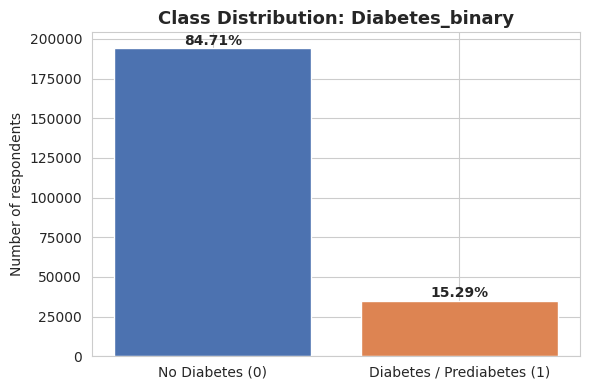


Imbalance ratio (majority : minority) ≈ 5.54 : 1


In [8]:
target_counts = df['Diabetes_binary'].value_counts().sort_index()
target_pct = (target_counts / target_counts.sum() * 100).round(2)

print("Class counts:")
print(target_counts)
print("\nClass percentages:")
print(target_pct)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['No Diabetes (0)', 'Diabetes / Prediabetes (1)'],
              target_counts.values,
              color=['#4C72B0', '#DD8452'])

for bar, pct in zip(bars, target_pct.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2000,
            f'{pct}%', ha='center', fontweight='bold')

ax.set_title('Class Distribution: Diabetes_binary', fontsize=13, fontweight='bold')
ax.set_ylabel('Number of respondents')
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150)
plt.show()

imbalance_ratio = target_counts[0] / target_counts[1]
print(f"\nImbalance ratio (majority : minority) ≈ {imbalance_ratio:.2f} : 1")


The dataset is imbalanced: roughly ~85-86% of records belong to class 0 ("no diabetes")
and ~14-15% belong to class 1 ("diabetes/prediabetes"). Under this distribution, Accuracy
is not a reliable metric on its own — a classifier that predicts class 0 for every record
would still score a high Accuracy while never correctly identifying a class-1 case. This is
why Precision, Recall, and F1-Score for the class-1 (positive) label are computed alongside
Accuracy in the model evaluation step, and why an imbalance-handling technique (class
weighting / SMOTE / undersampling) is applied before training in Step 4/5.

### 2.4 Identify feature types

In [9]:
target_col = 'Diabetes_binary'
feature_cols = [c for c in df.columns if c != target_col]

# Columns that are already binary flags (0/1 only)
binary_features = [c for c in feature_cols if df[c].nunique() == 2]

# Columns with more than 2 distinct values -> ordinal / continuous
ordinal_continuous_features = [c for c in feature_cols if c not in binary_features]

print(f"Binary flag features ({len(binary_features)}):")
print(binary_features)

print(f"\nOrdinal / continuous features ({len(ordinal_continuous_features)}):")
print(ordinal_continuous_features)


Binary flag features (14):
['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']

Ordinal / continuous features (7):
['BMI', 'GenHlth', 'MentHlth', 'PhysHlth', 'Age', 'Education', 'Income']


In [10]:
# Quick look at the value ranges of the ordinal/continuous group
# (helps decide which ones genuinely need scaling for the ANN)
df[ordinal_continuous_features].describe().T[['min', 'max', 'mean', 'std']]


,min,max,mean,std
BMI,12.0,98.0,28.687507,6.789204
GenHlth,1.0,5.0,2.601820,1.064962
MentHlth,0.0,30.0,3.509866,7.717643
PhysHlth,0.0,30.0,4.681219,9.050877
Age,1.0,13.0,8.085068,3.094451
Education,1.0,6.0,4.979741,0.992989
Income,1.0,8.0,5.888615,2.092888


## Step 3: EDA & Feature Engineering

This section computes:
1. Correlation of each feature with `Diabetes_binary`
2. Preparation for feature scaling (needed for the ANN)
3. One engineered feature — a BMI category bucket

### 3.1 Correlation with the target

Correlation of each feature with Diabetes_binary (sorted):
GenHlth                 0.276940
HighBP                  0.254318
DiffWalk                0.205302
BMI                     0.205086
HighChol                0.194944
Age                     0.177263
HeartDiseaseorAttack    0.168213
PhysHlth                0.156211
Stroke                  0.099193
CholCheck               0.072523
MentHlth                0.054153
Smoker                  0.045504
Sex                     0.032724
AnyHealthcare           0.025331
NoDocbcCost             0.020048
Fruits                 -0.024805
Veggies                -0.041734
HvyAlcoholConsump      -0.065950
PhysActivity           -0.100404
Education              -0.102686
Income                 -0.140659
Name: Diabetes_binary, dtype: float64


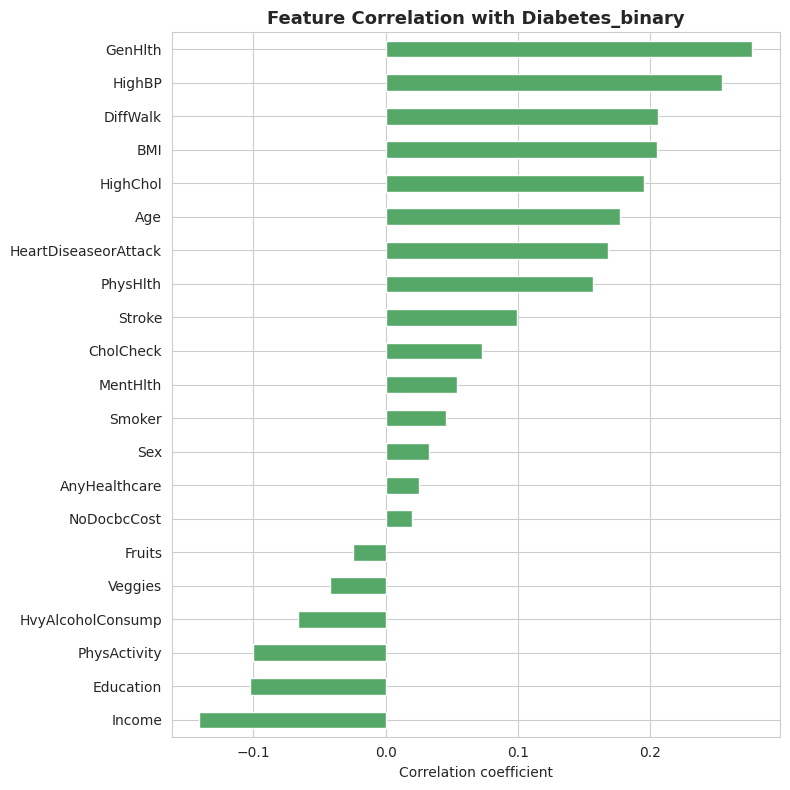

In [11]:
corr_with_target = df.corr(numeric_only=True)[target_col].drop(target_col).sort_values(ascending=False)

print("Correlation of each feature with Diabetes_binary (sorted):")
print(corr_with_target)

fig, ax = plt.subplots(figsize=(8, 8))
corr_with_target.sort_values().plot(kind='barh', ax=ax, color='#55A868')
ax.set_title('Feature Correlation with Diabetes_binary', fontsize=13, fontweight='bold')
ax.set_xlabel('Correlation coefficient')
plt.tight_layout()
plt.savefig('correlation_with_target.png', dpi=150)
plt.show()


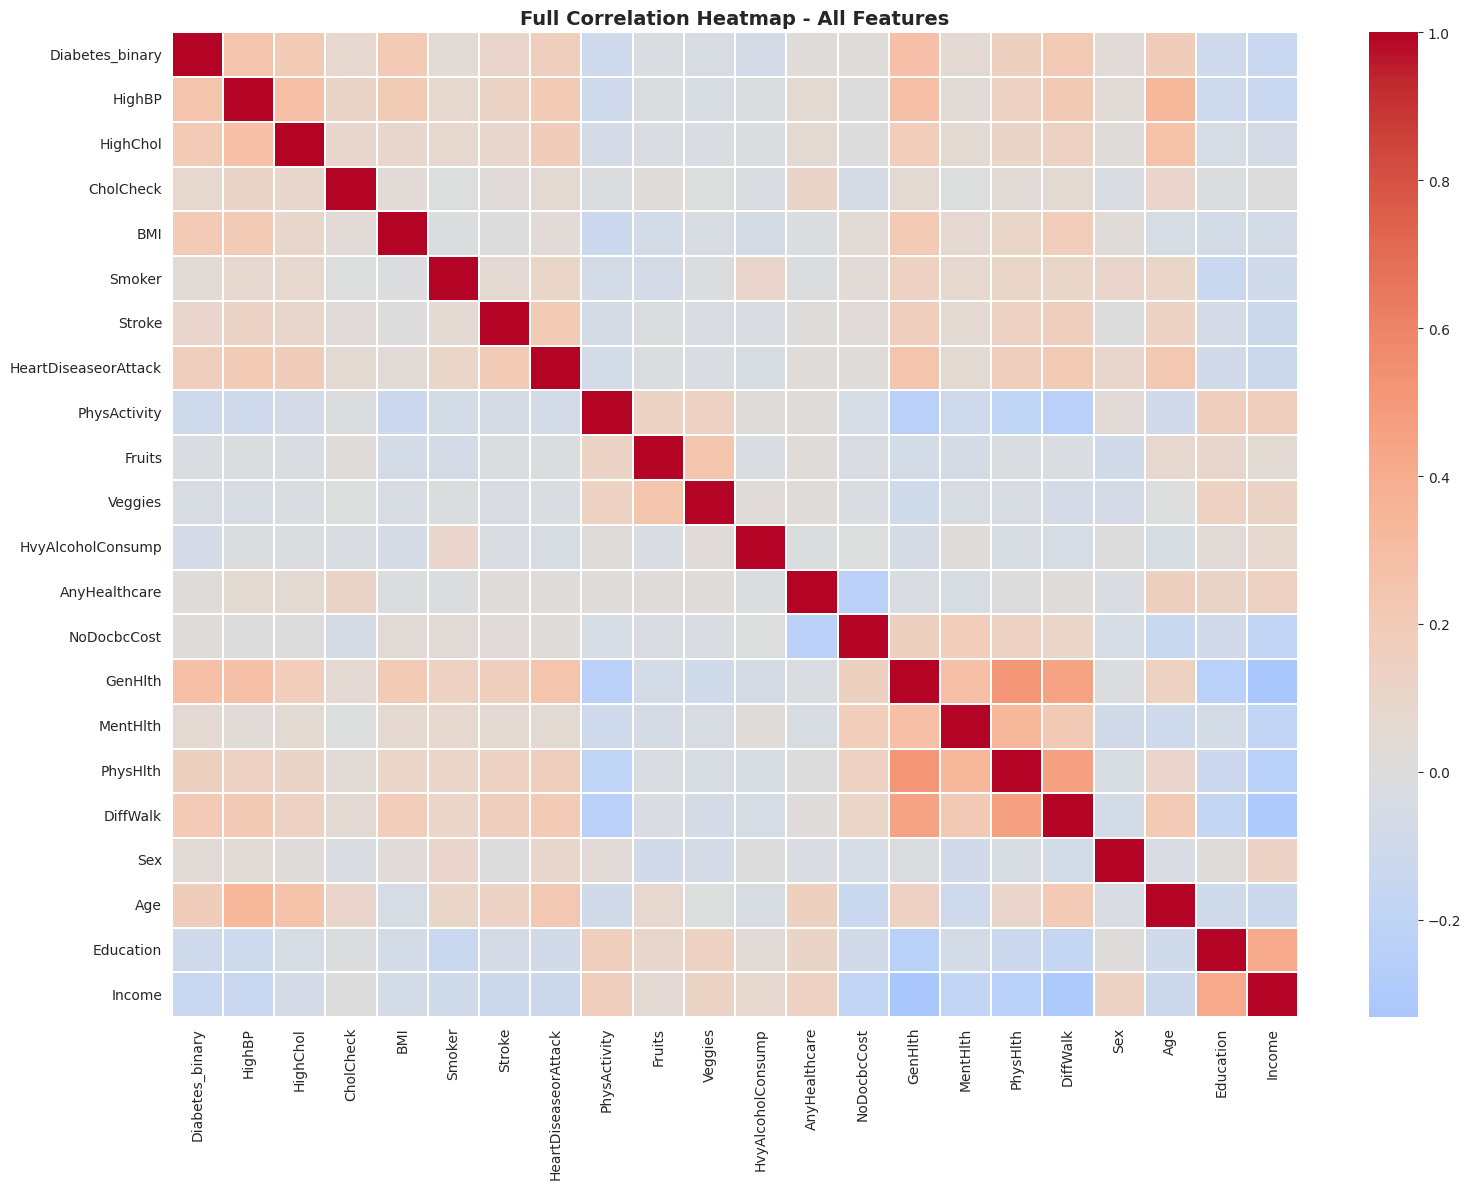

In [12]:
# Full correlation heatmap across ALL features (not just vs target)
# Useful to spot multicollinearity (e.g. between HighBP/HighChol/GenHlth)
plt.figure(figsize=(16, 12))
sns.heatmap(df.corr(numeric_only=True), cmap='coolwarm', center=0, annot=False, linewidths=0.3)
plt.title('Full Correlation Heatmap - All Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('full_correlation_heatmap.png', dpi=150)
plt.show()


These two charts are computed on the full deduplicated dataset, as exploratory statistics
only. The statistics that actually drive feature selection are recomputed on the training
set only in Section 4.1b, and produce the same ranking.

The features with the strongest positive correlation to `Diabetes_binary` are typically
`GenHlth` (general health rating), `HighBP`, `DiffWalk`, `BMI`, `HighChol`, and `Age`.
Features with correlation values near zero (e.g. `AnyHealthcare`, `Fruits`, `Veggies`) have
little linear relationship with the target on their own.

### 3.1b Correlation validity check (binary/ordinal variables) via Mutual Information

Pearson correlation is mathematically defined for continuous variables, but it remains a
valid statistic here for two specific cases:
- Between a **binary feature and the binary target**, Pearson's r is equivalent to the
  **phi coefficient**.
- Between a **continuous/ordinal feature and the binary target**, Pearson's r is equivalent
  to **point-biserial correlation**.

Both are standard, well-defined statistics for this exact combination of variable types.
The one limitation Pearson still has is that it only captures **linear** association — it
can miss non-linear or non-monotonic relationships. **Mutual Information** is computed as a
non-parametric cross-check, since it detects both linear and non-linear dependence between
each feature and the target.

In [13]:
from sklearn.feature_selection import mutual_info_classif

# Binary features are flagged as discrete for the MI estimator; the rest are treated as continuous
discrete_mask = [c in binary_features for c in feature_cols]

# Computed on a random sample for computational efficiency; MI estimates are stable at this sample size
mi_sample = df.sample(20000, random_state=42)

mi_scores = mutual_info_classif(
    mi_sample[feature_cols], mi_sample[target_col],
    discrete_features=discrete_mask, random_state=42
)
mi_series = pd.Series(mi_scores, index=feature_cols).sort_values(ascending=False)

print("Mutual Information scores (top 10):")
print(mi_series.head(10))

comparison = pd.DataFrame({
    'pearson_r': corr_with_target,
    'mutual_info': mi_series
}).sort_values('mutual_info', ascending=False)

comparison


Mutual Information scores (top 10):
GenHlth                 0.041618
HighBP                  0.033988
BMI                     0.025538
Age                     0.023677
HighChol                0.021447
DiffWalk                0.019870
HeartDiseaseorAttack    0.012298
PhysHlth                0.009977
Education               0.009240
Income                  0.008977
dtype: float64


,pearson_r,mutual_info
GenHlth,0.276940,0.041618
HighBP,0.254318,0.033988
BMI,0.205086,0.025538
Age,0.177263,0.023677
HighChol,0.194944,0.021447
DiffWalk,0.205302,0.019870
HeartDiseaseorAttack,0.168213,0.012298
PhysHlth,0.156211,0.009977
Education,-0.102686,0.009240
Income,-0.140659,0.008977


The Mutual Information ranking and the Pearson correlation ranking agree closely on the
top features (`GenHlth`, `HighBP`, `BMI`, `HighChol`, `Age`), which confirms that the
relationship between these features and the target is predominantly linear/monotonic rather
than a pattern Pearson would have missed.

### 3.1c Feature Selection Decision

Based on the combined Pearson and Mutual Information results, features are grouped into two
sets:
- **Full feature set (21 features):** used for the tree-based models (Decision Tree, Random
  Forest), since these models perform internal feature selection via split-gain and are not
  negatively affected by low-relevance features.
- **Reduced feature set (candidate):** obtained by removing features identified as having a
  negligible relationship with the target. Whether this actually benefits Naive Bayes (the
  model it is proposed for) rather than being assumed to, is tested empirically in
  Section 5.5.

**Choosing the cutoff:** with 229,474 rows (after removing exact duplicates in Section 2.1b), statistical significance testing on its own is
not a useful filter here — a p-value threshold is checked below to confirm this. Instead,
the cutoff uses **Cohen's (1988) convention for effect size**, where a correlation with
|r| < 0.1 is classified as a negligible effect, regardless of its statistical significance.
This is an established convention from the statistics literature rather than a threshold
chosen to fit this dataset.

In [14]:
from scipy.stats import pearsonr

p_values = {c: pearsonr(df[c], df[target_col])[1] for c in feature_cols}
p_values_series = pd.Series(p_values)

n_significant = (p_values_series < 0.05).sum()
print(f"Features with p < 0.05: {n_significant} out of {len(feature_cols)}")
print(f"Smallest |Pearson r| among all features: {corr_with_target.abs().min():.4f}, "
      f"p-value: {p_values_series[corr_with_target.abs().idxmin()]:.4g}")


Features with p < 0.05: 21 out of 21
Smallest |Pearson r| among all features: 0.0200, p-value: 7.636e-22


All 21 features are statistically significant at p < 0.05, including the weakest one
(`NoDocbcCost`, |r| = 0.020 on the deduplicated dataset; 0.016 on the training set in
Section 4.1b). At this sample size, statistical significance is expected
for almost any non-zero association, so it does not distinguish a practically relevant
feature from a practically irrelevant one. The Cohen's effect-size cutoff (|r| < 0.1) is
used instead, since it reflects the practical magnitude of the association rather than
whether it differs from zero.

In [15]:
COHEN_NEGLIGIBLE_THRESHOLD = 0.1  # Cohen (1988): |r| < 0.1 is a negligible effect size

low_relevance_features = corr_with_target[corr_with_target.abs() < COHEN_NEGLIGIBLE_THRESHOLD].index.tolist()
# Cross-check: keep only features that are ALSO in the bottom half of the MI ranking
low_mi_features = mi_series[mi_series < mi_series.median()].index.tolist()

features_to_drop = [f for f in low_relevance_features if f in low_mi_features]
reduced_feature_set = [f for f in feature_cols if f not in features_to_drop]

print(f"Full feature set: {len(feature_cols)} features")
print(f"Features below the Cohen negligible-effect threshold (|r| < {COHEN_NEGLIGIBLE_THRESHOLD}), "
      f"cross-checked against low Mutual Information rank: {features_to_drop}")
print(f"Reduced feature set: {len(reduced_feature_set)} features")
print(reduced_feature_set)


Full feature set: 21 features
Features below the Cohen negligible-effect threshold (|r| < 0.1), cross-checked against low Mutual Information rank: ['Stroke', 'CholCheck', 'MentHlth', 'Smoker', 'Sex', 'AnyHealthcare', 'NoDocbcCost', 'Fruits', 'Veggies', 'HvyAlcoholConsump']
Reduced feature set: 11 features
['HighBP', 'HighChol', 'BMI', 'HeartDiseaseorAttack', 'PhysActivity', 'GenHlth', 'PhysHlth', 'DiffWalk', 'Age', 'Education', 'Income']


### 3.2 Feature scaling (prep only — fit happens after train/test split)

**Important:** we only *decide/prepare* the scaling approach here. The actual
`.fit_transform()` must be applied **after** the train/test split in the modeling step
(Step 5), fitting the scaler on the training set only, to avoid data leakage. Doing it now
on the full dataset would leak information from the test set into training.

In [16]:
from sklearn.preprocessing import StandardScaler

# Columns that will benefit most from scaling (wide-range ordinal/continuous features).
# Pure binary 0/1 flags do not need scaling.
cols_to_scale = ['BMI', 'GenHlth', 'MentHlth', 'PhysHlth', 'Age', 'Education', 'Income']

print("Columns identified for scaling later (Step 5, after train/test split):")
print(cols_to_scale)

# Example of how the scaler will be used later (NOT applied yet on the full dataset):
scaler_preview = StandardScaler()
preview = scaler_preview.fit_transform(df[cols_to_scale].sample(5, random_state=42))
print("\nPreview of what scaled values look like (illustration only, on a 5-row sample):")
print(np.round(preview, 2))


Columns identified for scaling later (Step 5, after train/test split):
['BMI', 'GenHlth', 'MentHlth', 'PhysHlth', 'Age', 'Education', 'Income']

Preview of what scaled values look like (illustration only, on a 5-row sample):
[[-0.31 -0.44  2.    0.72 -0.79  1.54  1.75]
 [-1.33 -1.18 -0.5  -0.78  1.58  0.69  0.08]
 [ 0.2  -0.44 -0.5  -0.78 -0.79 -0.17  0.08]
 [-0.31  1.77 -0.5   1.63 -0.79 -1.03 -1.17]
 [ 1.74  0.29 -0.5  -0.78  0.79 -1.03 -0.75]]


### 3.2b Skewness check

Several non-binary features may be strongly skewed. Skewness matters for models that rely on
distances, gradients, or distributional assumptions (the ANN and Gaussian Naive Bayes), but
not for tree-based models, whose splits depend only on the *order* of values, so any
monotonic transformation such as a log leaves their splits unchanged. The check below
measures skewness and shows what a `log1p` transformation (log(1 + x), which is safe for the
many zero values) does to each strongly skewed feature. Whether to actually *use* the
transformation is decided later, per model, with training-set validation (Sections 5.5c
and 5.6b), rather than assumed here.

Skewness of the non-binary features (deduplicated dataset):
MentHlth     2.54
BMI          2.06
PhysHlth     2.04
GenHlth      0.35
Age         -0.38
Education   -0.69
Income      -0.78
dtype: float64

Strongly skewed features (|skew| > 1): ['MentHlth', 'BMI', 'PhysHlth']

Skewness after log1p, and share of exact zeros:
  MentHlth   raw skew =  2.54 | log1p skew =  1.38 | share of zeros = 66.4%
  BMI        raw skew =  2.06 | log1p skew =  0.67 | share of zeros = 0.0%
  PhysHlth   raw skew =  2.04 | log1p skew =  1.10 | share of zeros = 59.5%


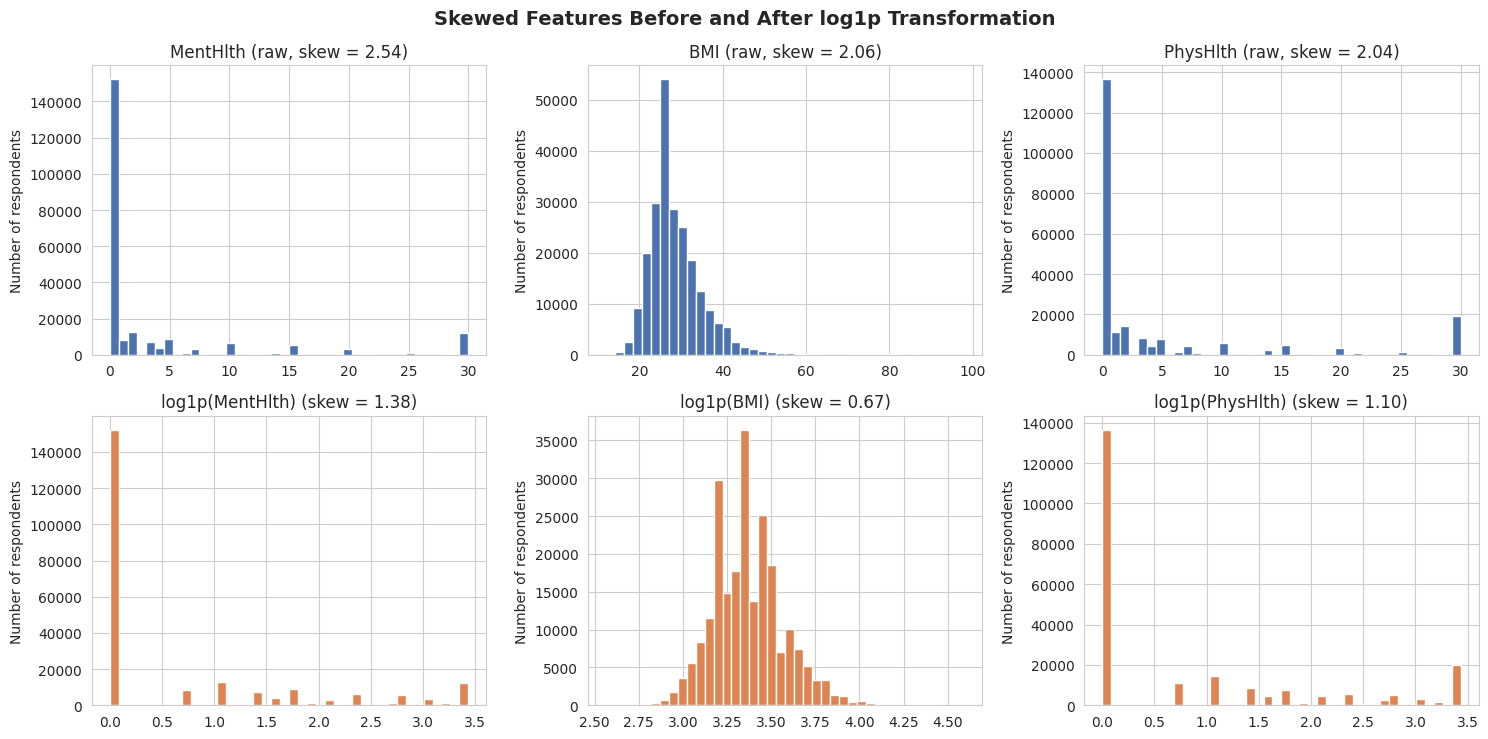

In [17]:
skewness = df[cols_to_scale].skew().sort_values(ascending=False)
print("Skewness of the non-binary features (deduplicated dataset):")
print(skewness.round(2))

# Rule of thumb: |skewness| > 1 indicates strong skew
SKEWED_FEATURES = skewness[skewness.abs() > 1].index.tolist()
print(f"\nStrongly skewed features (|skew| > 1): {SKEWED_FEATURES}")

print("\nSkewness after log1p, and share of exact zeros:")
for f in SKEWED_FEATURES:
    print(f"  {f:10s} raw skew = {df[f].skew():5.2f} | log1p skew = {np.log1p(df[f]).skew():5.2f} "
          f"| share of zeros = {(df[f] == 0).mean():.1%}")

fig, axes = plt.subplots(2, len(SKEWED_FEATURES), figsize=(5 * len(SKEWED_FEATURES), 7.5))
for j, f in enumerate(SKEWED_FEATURES):
    axes[0, j].hist(df[f], bins=40, color='#4C72B0')
    axes[0, j].set_title(f'{f} (raw, skew = {df[f].skew():.2f})', fontsize=12)
    axes[1, j].hist(np.log1p(df[f]), bins=40, color='#DD8452')
    axes[1, j].set_title(f'log1p({f}) (skew = {np.log1p(df[f]).skew():.2f})', fontsize=12)
    for r in range(2):
        axes[r, j].set_ylabel('Number of respondents')
plt.suptitle('Skewed Features Before and After log1p Transformation', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('skewness_log1p.png', dpi=150)
plt.show()

`BMI` becomes close to symmetric after `log1p`. `MentHlth` and `PhysHlth` remain skewed
even after the transformation, because most respondents report **zero** poor-health days:
a log cannot spread out a large spike of identical values. These two features are
zero-inflated rather than simply long-tailed, which limits what any transformation can
achieve for them.

### 3.3 Feature engineering: BMI category bucket

In [18]:
def bmi_to_category(bmi):
    """Standard clinical BMI categories (WHO classification)."""
    if bmi < 18.5:
        return 'Underweight'
    elif bmi < 25:
        return 'Normal'
    elif bmi < 30:
        return 'Overweight'
    else:
        return 'Obese'

df['BMI_Category'] = df['BMI'].apply(bmi_to_category)

category_order = ['Underweight', 'Normal', 'Overweight', 'Obese']
df['BMI_Category'] = pd.Categorical(df['BMI_Category'], categories=category_order, ordered=True)

print(df['BMI_Category'].value_counts().reindex(category_order))


BMI_Category
Underweight     3052
Normal         58842
Overweight     82723
Obese          84857
Name: count, dtype: int64


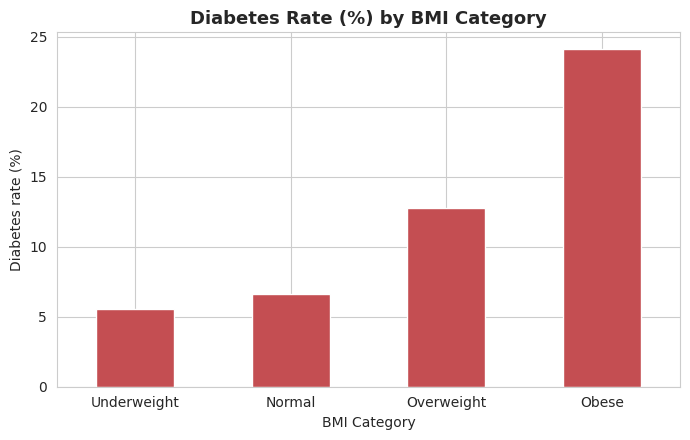

BMI_Category
Underweight     5.54
Normal          6.64
Overweight     12.77
Obese          24.10
Name: Diabetes_binary, dtype: float64


In [19]:
# Diabetes rate by BMI category
diabetes_rate_by_bmi = df.groupby('BMI_Category', observed=True)[target_col].mean() * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
diabetes_rate_by_bmi.reindex(category_order).plot(kind='bar', ax=ax, color='#C44E52')
ax.set_title('Diabetes Rate (%) by BMI Category', fontsize=13, fontweight='bold')
ax.set_ylabel('Diabetes rate (%)')
ax.set_xlabel('BMI Category')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('diabetes_rate_by_bmi_category.png', dpi=150)
plt.show()

print(diabetes_rate_by_bmi.reindex(category_order).round(2))


The diabetes rate increases across the BMI categories from `Underweight`/`Normal` through
to `Obese`, consistent with the positive correlation observed between `BMI` and
`Diabetes_binary` in the previous section.

**Scope of this feature:** `BMI_Category` is used here for exploratory interpretation
only — it is not added to `feature_cols` and is not seen by any model in this notebook.
It is a discretised transform of `BMI`, which is already present as a continuous feature;
adding both would introduce collinearity without contributing new information to the
tree-based models, and the continuous form is preferable for the ANN. Its role in this
notebook is to make the BMI–diabetes relationship interpretable in Section 3, not to
serve as model input.

## Step 4: Train/Test Split & Imbalance Handling

Three common techniques exist for handling class imbalance: class weighting, SMOTE
(synthetic oversampling), and random undersampling.

**Technique selected: class weighting.** The other two are not well suited to this
particular dataset:
- **SMOTE** generates synthetic samples by linear interpolation between existing points.
  Most features in this dataset (`HighBP`, `Smoker`, `Stroke`, etc.) are binary flags —
  interpolating between two binary points produces fractional values (e.g. 0.37) that do
  not correspond to a valid category, which is not meaningful for these features.
- **Random undersampling** would discard the majority of the majority-class rows to match
  the minority class (155,501 vs. 28,078 rows in the 183,579-row training set), removing a
  large amount of real data at this dataset's scale.

**Class weighting** avoids both problems: it does not alter or synthesize any feature
values, and it does not discard data. It works by assigning a higher penalty to
misclassifying the minority class during training, applied through the `class_weight`
parameter (Decision Tree, Random Forest, Keras ANN) or an equivalent adjusted `priors`
parameter (Gaussian Naive Bayes, which does not expose `class_weight` directly).

### 4.0 Testing Methodology

All models in this notebook are trained and evaluated under the same protocol, summarized
here in one place rather than left to be pieced together from individual sections:

- **Split:** the dataset is split 80/20 into training and test sets using stratified
  sampling on the target, preserving the 84.71% / 15.29% class ratio in both subsets
  (Section 4.1).
- **Reproducibility:** a fixed random seed (`random_state = 42`) is used throughout — for
  the train/test split, model initialization, and every hyperparameter search — so the
  results in this notebook are reproducible from a fresh run.
- **Leakage avoidance:** every data-driven decision (feature-selection statistics in
  Section 3.1c, the `StandardScaler` fit in Section 4.3, the class-weight computation in
  Section 4.2, and the ANN architecture/hyperparameter choice in Section 5.6) is made using
  the training set only. The imbalance-technique comparison (Section 4.2b) and the Naive Bayes
  assumption check (Section 5.5b) also use cross-validation on the training set only. The
  test set is used once per model to report final metrics (Section 5.7); two later analyses
  reuse those same test-set predictions (the reduced-feature diagnostic in Section 5.6e and
  the bootstrap in Section 5.10b), but neither of them changes any modelling decision.
- **Beyond the single split:** 10-fold stratified cross-validation on the training set
  (Section 5.9) and a paired bootstrap on the test set (Section 5.10b) are used on top of
  the single test-set evaluation, to check that the model ranking is statistically robust
  rather than an artifact of one particular data split.

### 4.1 Train/test split

In [20]:
from sklearn.model_selection import train_test_split

X = df[feature_cols]
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Training set: {X_train.shape[0]} rows, {X_train.shape[1]} features")
print(f"Test set: {X_test.shape[0]} rows, {X_test.shape[1]} features")


Training set: 183579 rows, 21 features
Test set: 45895 rows, 21 features


In [21]:
# Stratified split preserves the same class proportions in both subsets
train_dist = (y_train.value_counts(normalize=True) * 100).round(2)
test_dist = (y_test.value_counts(normalize=True) * 100).round(2)

print("Class distribution in training set (%):")
print(train_dist)
print("\nClass distribution in test set (%):")
print(test_dist)


Class distribution in training set (%):
Diabetes_binary
0.0    84.71
1.0    15.29
Name: proportion, dtype: float64

Class distribution in test set (%):
Diabetes_binary
0.0    84.71
1.0    15.29
Name: proportion, dtype: float64


### 4.1b Recompute Feature Selection on Training Data Only (fixes data leakage)

The Pearson correlation, Mutual Information, and Cohen's effect-size cutoff computed in
Step 3 were calculated on the **full dataset**, before the train/test split existed. Using
those statistics to decide `reduced_feature_set` means that decision was informed, in part,
by rows that later became the test set — a data leakage issue, structurally the same as the
one already avoided for `StandardScaler` in Section 4.3 below.

Step 3's correlation/MI values remain valid as **exploratory/descriptive statistics** on the
dataset as a whole, and the visualizations produced from them are not affected. However,
`corr_with_target`, `mi_series`, and `reduced_feature_set` are recomputed here using
**`X_train`/`y_train` only**, and it is this training-only version that is actually used by
the models in Step 5 (Naive Bayes, ANN) and by the feature-importance comparison in
Section 5.4 — the same variable names are reused so no other code needs to change.

In [22]:
from sklearn.feature_selection import mutual_info_classif

train_df_for_selection = X_train.copy()
train_df_for_selection[target_col] = y_train.values

# Pearson correlation, computed on the training set only
corr_with_target = train_df_for_selection.corr(numeric_only=True)[target_col].drop(target_col).sort_values(ascending=False)

# Mutual Information, computed on a sample of the training set only
mi_train_sample = train_df_for_selection.sample(20000, random_state=42)
mi_scores = mutual_info_classif(
    mi_train_sample[feature_cols], mi_train_sample[target_col],
    discrete_features=discrete_mask, random_state=42
)
mi_series = pd.Series(mi_scores, index=feature_cols).sort_values(ascending=False)

# Same Cohen's effect-size cutoff as Step 3, reapplied to the training-only statistics
low_relevance_features = corr_with_target[corr_with_target.abs() < COHEN_NEGLIGIBLE_THRESHOLD].index.tolist()
low_mi_features = mi_series[mi_series < mi_series.median()].index.tolist()
features_to_drop = [f for f in low_relevance_features if f in low_mi_features]
reduced_feature_set = [f for f in feature_cols if f not in features_to_drop]

print("Feature selection recomputed on the training set only:")
print(f"Features dropped: {features_to_drop}")
print(f"Reduced feature set ({len(reduced_feature_set)} features): {reduced_feature_set}")


Feature selection recomputed on the training set only:
Features dropped: ['Stroke', 'CholCheck', 'MentHlth', 'Smoker', 'Sex', 'AnyHealthcare', 'NoDocbcCost', 'Fruits', 'Veggies', 'HvyAlcoholConsump']
Reduced feature set (11 features): ['HighBP', 'HighChol', 'BMI', 'HeartDiseaseorAttack', 'PhysActivity', 'GenHlth', 'PhysHlth', 'DiffWalk', 'Age', 'Education', 'Income']


### 4.2 Compute class weights

In [23]:
from sklearn.utils.class_weight import compute_class_weight

class_weights_array = compute_class_weight(
    class_weight='balanced', classes=np.unique(y_train), y=y_train
)
class_weight_dict = dict(zip(np.unique(y_train).astype(int), class_weights_array))

print("Class weights computed from the training set:")
print(class_weight_dict)

# Gaussian Naive Bayes has no class_weight parameter; the equivalent adjustment is to set
# balanced priors explicitly instead of letting the model estimate them from the (imbalanced)
# training data
gnb_priors = [0.5, 0.5]
print("\nEquivalent balanced priors for GaussianNB:", gnb_priors)


Class weights computed from the training set:
{np.int64(0): np.float64(0.5902823776052887), np.int64(1): np.float64(3.269089678752048)}

Equivalent balanced priors for GaussianNB: [0.5, 0.5]


### 4.2b Empirical Validation of the Imbalance-Handling Choice

Section 4 above rejected SMOTE and random undersampling on theoretical grounds. Since a
theoretical argument is not the same as evidence, both rejected techniques are tested here
directly against class weighting, using the same Decision Tree configuration (`max_depth=8,
min_samples_leaf=100`) trained three different ways, so that the imbalance-handling
technique is the only thing that varies.

**Evaluation uses 5-fold stratified cross-validation on the training set only**, not the
test set, because this comparison drives a modelling decision. SMOTE and undersampling are
placed inside an `imblearn` Pipeline so that resampling is applied to each fold's training
rows only, and the validation fold always keeps its real, unresampled class distribution.

In [24]:
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

imb_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
imb_scoring = {'Recall': 'recall', 'Precision': 'precision', 'F1-Score': 'f1', 'Accuracy': 'accuracy'}

imbalance_candidates = {
    'Class Weighting': DecisionTreeClassifier(max_depth=8, min_samples_leaf=100,
                                              class_weight='balanced', random_state=42),
    'SMOTE': ImbPipeline([('resample', SMOTE(random_state=42)),
                          ('model', DecisionTreeClassifier(max_depth=8, min_samples_leaf=100, random_state=42))]),
    'Random Undersampling': ImbPipeline([('resample', RandomUnderSampler(random_state=42)),
                                         ('model', DecisionTreeClassifier(max_depth=8, min_samples_leaf=100, random_state=42))]),
}

imbalance_comparison = {}
imbalance_fold_recall = {}
for name, model in imbalance_candidates.items():
    cv_res = cross_validate(model, X_train, y_train, cv=imb_cv, scoring=imb_scoring)
    imbalance_fold_recall[name] = cv_res['test_Recall']
    imbalance_comparison[name] = {}
    for m in imb_scoring:
        imbalance_comparison[name][f'{m} (mean)'] = cv_res[f'test_{m}'].mean()
    imbalance_comparison[name]['Recall (std)'] = cv_res['test_Recall'].std()

# Direct evidence for the "fractional binary feature" claim: inspect SMOTE-synthesised rows
# (SMOTE fitted on the training set only; the test set is not involved)
X_train_smote, y_train_smote = SMOTE(random_state=42).fit_resample(X_train, y_train)
synthetic_rows = X_train_smote.iloc[len(X_train):]
fractional_rate = synthetic_rows[binary_features].apply(lambda col: ((col % 1) != 0).mean())
print("Fraction of SMOTE-synthesised rows with a non-integer value, per binary feature:")
print(fractional_rate[fractional_rate > 0].sort_values(ascending=False).round(3))

_, y_train_rus = RandomUnderSampler(random_state=42).fit_resample(X_train, y_train)
print(f"\nUndersampled training set: {len(y_train_rus)} rows (vs. {len(y_train)} original)")

print("\nPer-fold Recall (5-fold CV, training set only):")
print(pd.DataFrame(imbalance_fold_recall, index=[f'Fold {i}' for i in range(1, 6)]).round(4))

print("\nDecision Tree performance under each imbalance-handling technique (5-fold CV, training set only):")
pd.DataFrame(imbalance_comparison).T.round(4)


Fraction of SMOTE-synthesised rows with a non-integer value, per binary feature:
Smoker                  0.296
Fruits                  0.294
Sex                     0.277
PhysActivity            0.277
HighChol                0.262
Veggies                 0.234
HighBP                  0.216
DiffWalk                0.214
HeartDiseaseorAttack    0.210
NoDocbcCost             0.128
Stroke                  0.116
AnyHealthcare           0.052
HvyAlcoholConsump       0.033
CholCheck               0.010
dtype: float64

Undersampled training set: 56156 rows (vs. 183579 original)

Per-fold Recall (5-fold CV, training set only):
        Class Weighting   SMOTE  Random Undersampling
Fold 1           0.7553  0.5044                0.7484
Fold 2           0.7441  0.4809                0.7573
Fold 3           0.7537  0.4498                0.7596
Fold 4           0.7527  0.4838                0.7701
Fold 5           0.7678  0.4935                0.7647

Decision Tree performance under each imbalance-ha

,Recall (mean),Precision (mean),F1-Score (mean),Accuracy (mean),Recall (std)
Class Weighting,0.7547,0.3111,0.4405,0.7067,0.0076
SMOTE,0.4825,0.3919,0.4322,0.8062,0.0183
Random Undersampling,0.7600,0.3066,0.4369,0.7003,0.0073


Evaluated with cross-validation on the training set only, the results confirm the objection
to SMOTE with direct evidence: its mean Recall is far lower than either alternative, and a
substantial fraction of its synthesised rows take non-integer values on features that are
only ever 0 or 1 in the real data.

Class weighting and random undersampling are, however, **statistically indistinguishable on
Recall**: their mean difference is smaller than the fold-to-fold standard deviation, and
each technique wins some folds and loses others. The choice between them therefore rests on
the secondary criteria rather than on Recall alone: class weighting keeps the complete
training set (undersampling discards roughly 70% of it) and scores slightly higher on
Precision, F1-Score, and Accuracy. Class weighting remains the technique used throughout
the rest of this notebook, on those grounds rather than on a claimed Recall advantage.

### 4.3 Feature scaling (fit on training set only)

The scaler decided on in Step 3.2 is fitted here, on the training set only, and then
applied to both the training and test sets. This produces a scaled version of the data for
use by the ANN in Step 5, without leaking any information from the test set into the
fitting process.

In [25]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_test_scaled[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

print("Scaled columns (mean/std after scaling, training set):")
X_train_scaled[cols_to_scale].agg(['mean', 'std']).T.round(3)


Scaled columns (mean/std after scaling, training set):


,mean,std
BMI,-0.0,1.0
GenHlth,0.0,1.0
MentHlth,0.0,1.0
PhysHlth,0.0,1.0
Age,0.0,1.0
Education,-0.0,1.0
Income,-0.0,1.0


### Summary of objects produced in Step 4

| Object | Contents | Used by |
|---|---|---|
| `X_train`, `X_test`, `y_train`, `y_test` | Full 21-feature set, unscaled | Decision Tree, Random Forest |
| `X_train_scaled`, `X_test_scaled` | Same split, `cols_to_scale` standardized | ANN |
| `reduced_feature_set` (from Step 3) | 11-feature candidate set (10 low-relevance features removed) | Candidate input for Naive Bayes, tested against the full set in Section 5.5 |
| `class_weight_dict` | `{0: weight, 1: weight}` from `compute_class_weight` | Decision Tree, Random Forest, ANN |
| `gnb_priors` | `[0.5, 0.5]` | Gaussian Naive Bayes |

These objects are used directly in Step 5 to train and evaluate the five models developed in this notebook.

## Step 5: Model Training & Evaluation

The four required models — Decision Tree, Random Forest, Gaussian Naive Bayes, and a
Multilayer ANN — are trained and evaluated on the same test set, plus one additional model
beyond the minimum requirement (Section 5.3b). Each model uses the inputs prepared in
Step 4 (see the summary table above). Evaluation uses Accuracy, Precision, Recall, and
F1-Score, computed for the positive class (`Diabetes_binary = 1`), plus ROC-AUC and PR-AUC
where a predicted probability is available.

**On not using LSTM/RNN as the additional model:** LSTM and RNN architectures are designed
for data with a sequential or temporal dependency between observations (e.g. time series,
text). Each row of this dataset is one independent survey respondent from a single point in
time (BRFSS 2015) — there is no ordering or sequential relationship between rows, and no
temporal relationship between the 21 features themselves. Reshaping the feature vector into
an artificial "sequence" purely to use an LSTM would not model any real sequential
structure and would not be an appropriate use of that architecture. Instead, **XGBoost** — a
gradient-boosted tree ensemble well suited to tabular data of this kind — is added as the
additional model beyond the four required.

### 5.0 Evaluation helper

In [26]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, classification_report
)

results = {}
confusion_matrices = {}

def evaluate_model(name, y_true, y_pred, y_proba=None):
    metrics = {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, pos_label=1),
        'Recall': recall_score(y_true, y_pred, pos_label=1),
        'F1-Score': f1_score(y_true, y_pred, pos_label=1),
    }
    if y_proba is not None:
        metrics['ROC-AUC'] = roc_auc_score(y_true, y_proba)
        metrics['PR-AUC'] = average_precision_score(y_true, y_proba)

    results[name] = metrics
    confusion_matrices[name] = confusion_matrix(y_true, y_pred)

    print(f"--- {name} ---")
    print(classification_report(y_true, y_pred, target_names=['No Diabetes', 'Diabetes']))
    return metrics


### 5.1 Baseline (Dummy Classifier)

Before evaluating the four required models, a baseline is established using a classifier
that ignores the input features entirely and predicts according to the observed class
distribution. Any model that fails to clearly outperform this baseline is not demonstrating
real predictive skill on this dataset. This baseline is evaluated once on the test set and
is not included in the cross-validation comparison in Section 5.9, since it involves no
learning process to validate.

In [27]:
from sklearn.dummy import DummyClassifier

baseline_model = DummyClassifier(strategy='stratified', random_state=42)
baseline_model.fit(X_train, y_train)

baseline_pred = baseline_model.predict(X_test)
baseline_proba = baseline_model.predict_proba(X_test)[:, 1]

evaluate_model('Baseline (Dummy)', y_test, baseline_pred, baseline_proba)


--- Baseline (Dummy) ---


              precision    recall  f1-score   support

 No Diabetes       0.85      0.85      0.85     38876
    Diabetes       0.16      0.16      0.16      7019

    accuracy                           0.74     45895
   macro avg       0.50      0.50      0.50     45895
weighted avg       0.74      0.74      0.74     45895



{'Accuracy': 0.7426299161128663,
 'Precision': 0.15778951877766673,
 'Recall': 0.15742983330958826,
 'F1-Score': 0.1576094708315504,
 'ROC-AUC': 0.5028583470488676,
 'PR-AUC': 0.15370013050985132}

### 5.2 Decision Tree

Hyperparameters (`max_depth`, `min_samples_leaf`) are tuned with `GridSearchCV` (3-fold, on
the training set) instead of being fixed by hand. The search is scored on **Recall**, matching
the priority metric established for this project — using a different scorer (e.g. Accuracy)
here would make the reported "best" tree inconsistent with the stated priority.

**Grid width check:** an initial, narrower grid (`max_depth` in [4,6,8,10,12],
`min_samples_leaf` in [1,20,100]) selected `min_samples_leaf = 100` — the largest value
tested. A parameter landing on the edge of its search grid is a sign the grid may be too
narrow, since the true optimum could lie further in that direction. The grid below was
widened specifically to check this, extending `min_samples_leaf` up to 3200; the search
below confirms where the score actually stops improving.

In [28]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

dt_param_grid = {
    'max_depth': [4, 6, 8, 10, 12, 14],
    'min_samples_leaf': [20, 100, 200, 400, 800, 1600, 3200]
}

dt_search = GridSearchCV(
    DecisionTreeClassifier(class_weight='balanced', random_state=42),
    dt_param_grid, scoring='recall', cv=3, n_jobs=-1
)
dt_search.fit(X_train, y_train)

dt_model = dt_search.best_estimator_
print(f"Best Decision Tree parameters (by CV Recall): {dt_search.best_params_}")
print(f"Best CV Recall during search: {dt_search.best_score_:.4f}")

dt_pred = dt_model.predict(X_test)
dt_proba = dt_model.predict_proba(X_test)[:, 1]

evaluate_model('Decision Tree', y_test, dt_pred, dt_proba)


Best Decision Tree parameters (by CV Recall): {'max_depth': 8, 'min_samples_leaf': 1600}
Best CV Recall during search: 0.7832
--- Decision Tree ---
              precision    recall  f1-score   support

 No Diabetes       0.94      0.67      0.78     38876
    Diabetes       0.30      0.78      0.43      7019

    accuracy                           0.69     45895
   macro avg       0.62      0.73      0.61     45895
weighted avg       0.85      0.69      0.73     45895



{'Accuracy': 0.6870900969604532,
 'Precision': 0.2994865632510378,
 'Recall': 0.7811654081778031,
 'F1-Score': 0.4329766652189363,
 'ROC-AUC': 0.8014316373292246,
 'PR-AUC': 0.4077307568042294}

In [29]:
# Confirm convergence: check whether the score keeps rising past the selected min_samples_leaf,
# or genuinely peaks and then declines (the latter confirms a true, non-boundary optimum)
cv_results_dt = pd.DataFrame(dt_search.cv_results_)
convergence_check = (
    cv_results_dt[cv_results_dt['param_max_depth'] == dt_search.best_params_['max_depth']]
    [['param_min_samples_leaf', 'mean_test_score']]
    .sort_values('param_min_samples_leaf')
)
print("Recall vs. min_samples_leaf, at the selected max_depth:")
print(convergence_check.to_string(index=False))


Recall vs. min_samples_leaf, at the selected max_depth:
 param_min_samples_leaf  mean_test_score
                     20         0.769358
                    100         0.767790
                    200         0.771744
                    400         0.770817
                    800         0.764336
                   1600         0.783175
                   3200         0.724518


### 5.3 Random Forest

Hyperparameters (`n_estimators`, `max_depth`, `min_samples_leaf`) are tuned with
`RandomizedSearchCV`, scored on Recall with `cv=3` — the same number of folds used for
Decision Tree and XGBoost, so that all three tree-based searches are evaluated with the
same statistical rigor rather than one being cheaper than the others for convenience.

**Grid width check:** an initial, narrower search (`n_estimators` in [100,150,200],
`max_depth` in [8,12,16], `min_samples_leaf` in [1,10,50]) selected values at the edge of
every one of the three ranges (`n_estimators = 200`, `max_depth = 8`, `min_samples_leaf =
50`). As with the Decision Tree, this is a sign the grid may be too narrow. The grid below
widens all three dimensions to check whether the score keeps improving past those edges or
genuinely plateaus.

In [30]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

rf_param_dist = {
    'n_estimators': [100, 150, 200, 300],
    'max_depth': [4, 6, 8, 12, 16, 20],
    'min_samples_leaf': [10, 50, 100, 200, 400]
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=1),
    rf_param_dist, n_iter=8, scoring='recall', cv=3, random_state=42, n_jobs=-1
)
rf_search.fit(X_train, y_train)

rf_model = rf_search.best_estimator_
print(f"Best Random Forest parameters (by CV Recall): {rf_search.best_params_}")
print(f"Best CV Recall during search: {rf_search.best_score_:.4f}")

rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]

evaluate_model('Random Forest', y_test, rf_pred, rf_proba)


Best Random Forest parameters (by CV Recall): {'n_estimators': 150, 'min_samples_leaf': 200, 'max_depth': 12}
Best CV Recall during search: 0.7733


--- Random Forest ---
              precision    recall  f1-score   support

 No Diabetes       0.95      0.69      0.80     38876
    Diabetes       0.32      0.78      0.45      7019

    accuracy                           0.71     45895
   macro avg       0.63      0.74      0.62     45895
weighted avg       0.85      0.71      0.75     45895



{'Accuracy': 0.7063514544067981,
 'Precision': 0.3151900183150183,
 'Recall': 0.7845846986750249,
 'F1-Score': 0.4497162222857376,
 'ROC-AUC': 0.8148618691279961,
 'PR-AUC': 0.4387144694273761}

In [31]:
# Confirm convergence on max_depth specifically, since RandomizedSearchCV's random sampling
# does not guarantee even coverage: fix the other two parameters at their selected values and
# sweep max_depth exhaustively (cv=3, matching the main search above), including an
# unlimited-depth option
from sklearn.model_selection import GridSearchCV as _GridSearchCV_check

depth_check = _GridSearchCV_check(
    RandomForestClassifier(
        n_estimators=rf_search.best_params_['n_estimators'],
        min_samples_leaf=rf_search.best_params_['min_samples_leaf'],
        class_weight='balanced', random_state=42, n_jobs=-1
    ),
    {'max_depth': [8, 12, 16, 20, 24, None]}, scoring='recall', cv=3, n_jobs=1
)
depth_check.fit(X_train, y_train)
depth_results = pd.DataFrame(depth_check.cv_results_)[['param_max_depth', 'mean_test_score']]
print("Recall vs. max_depth, at the selected n_estimators/min_samples_leaf:")
print(depth_results.to_string(index=False))


Recall vs. max_depth, at the selected n_estimators/min_samples_leaf:
param_max_depth  mean_test_score
              8         0.769179
             12         0.773346
             16         0.773346
             20         0.773346
             24         0.773167
           None         0.773167


### 5.3b XGBoost (Additional Model)

Added beyond the four required models, as discussed above. XGBoost does not accept a
`class_weight` argument; the equivalent mechanism is `scale_pos_weight`, set to the ratio of
negative to positive samples in the training set — the same imbalance ratio used to derive
`class_weight_dict` for the other models, expressed in the form XGBoost expects.

**Grid width check:** an initial, narrower search (`n_estimators` in [100,150,200],
`max_depth` in [4,6,8], `learning_rate` in [0.05,0.1,0.2]) selected values at the edge of
every range (`n_estimators = 100`, `max_depth = 4`, `learning_rate = 0.05`). The grid below
widens all three dimensions to check this, the same way as for Decision Tree and Random
Forest above. Because the selected `n_estimators` can still land on the upper edge of this
grid, an extra convergence check after the search extends `n_estimators` further, with the
other two parameters fixed at their selected values.

In [32]:
from xgboost import XGBClassifier

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight (negative:positive ratio in training set): {scale_pos_weight:.4f}")

xgb_param_grid = {
    'n_estimators': [50, 75, 100, 150],
    'max_depth': [2, 3, 4, 6],
    'learning_rate': [0.01, 0.03, 0.05, 0.1]
}

xgb_search = GridSearchCV(
    XGBClassifier(scale_pos_weight=scale_pos_weight, random_state=42,
                  eval_metric='logloss', n_jobs=1),
    xgb_param_grid, scoring='recall', cv=3, n_jobs=-1
)
xgb_search.fit(X_train, y_train)

xgb_model = xgb_search.best_estimator_
print(f"Best XGBoost parameters (by CV Recall): {xgb_search.best_params_}")
print(f"Best CV Recall during search: {xgb_search.best_score_:.4f}")

xgb_pred = xgb_model.predict(X_test)
xgb_proba = xgb_model.predict_proba(X_test)[:, 1]

evaluate_model('XGBoost', y_test, xgb_pred, xgb_proba)


scale_pos_weight (negative:positive ratio in training set): 5.5382


Best XGBoost parameters (by CV Recall): {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 150}
Best CV Recall during search: 0.7830
--- XGBoost ---
              precision    recall  f1-score   support

 No Diabetes       0.95      0.69      0.80     38876
    Diabetes       0.32      0.79      0.45      7019

    accuracy                           0.70     45895
   macro avg       0.63      0.74      0.62     45895
weighted avg       0.85      0.70      0.75     45895



{'Accuracy': 0.7047608671968624,
 'Precision': 0.31524752475247525,
 'Recall': 0.7938452771050007,
 'F1-Score': 0.45128371264274725,
 'ROC-AUC': 0.8185114885425344,
 'PR-AUC': 0.44558024232376847}

In [33]:
# Convergence check for n_estimators: extend beyond the upper edge of the main grid, with
# learning_rate and max_depth fixed at their selected values (cv=3, scored on Recall, training set only)
xgb_n_check = GridSearchCV(
    XGBClassifier(learning_rate=xgb_search.best_params_['learning_rate'],
                  max_depth=xgb_search.best_params_['max_depth'],
                  scale_pos_weight=scale_pos_weight, random_state=42,
                  eval_metric='logloss', n_jobs=-1),
    {'n_estimators': [100, 150, 200, 300, 400]}, scoring='recall', cv=3, n_jobs=1
)
xgb_n_check.fit(X_train, y_train)
print("Recall vs. n_estimators, at the selected learning_rate/max_depth:")
print(pd.DataFrame(xgb_n_check.cv_results_)[['param_n_estimators', 'mean_test_score']].to_string(index=False))

Recall vs. n_estimators, at the selected learning_rate/max_depth:
 param_n_estimators  mean_test_score
                100         0.780932
                150         0.782962
                200         0.782249
                300         0.780789
                400         0.779792


### 5.4 Feature Importance vs. EDA Ranking

The Decision Tree, Random Forest, and XGBoost each expose a `feature_importances_`
attribute, reflecting how much each feature contributed to reducing impurity (or loss)
across their splits. This is compared against the Pearson correlation and Mutual
Information rankings computed in Step 3, to check whether the features the models
actually rely on match the features identified as relevant during EDA.

In [34]:
from scipy.stats import spearmanr

importance_df = pd.DataFrame({
    'DecisionTree_Importance': dt_model.feature_importances_,
    'RandomForest_Importance': rf_model.feature_importances_,
    'XGBoost_Importance': xgb_model.feature_importances_,
    'Pearson_r': corr_with_target.reindex(feature_cols).values,
    'Mutual_Info': mi_series.reindex(feature_cols).values
}, index=feature_cols)

importance_df_sorted = importance_df.sort_values('RandomForest_Importance', ascending=False)
importance_df_sorted.round(4)


,DecisionTree_Importance,RandomForest_Importance,XGBoost_Importance,Pearson_r,Mutual_Info
HighBP,0.4636,0.2540,0.6536,0.2543,0.0344
GenHlth,0.2753,0.2099,0.0864,0.2751,0.0447
BMI,0.1126,0.1407,0.0286,0.2047,0.0304
Age,0.1015,0.1098,0.0317,0.1778,0.0220
HighChol,0.0400,0.1044,0.0610,0.1939,0.0183
DiffWalk,0.0000,0.0571,0.0244,0.2042,0.0164
HeartDiseaseorAttack,0.0004,0.0310,0.0256,0.1686,0.0127
Income,0.0010,0.0212,0.0078,-0.1391,0.0162
PhysHlth,0.0000,0.0200,0.0024,0.1552,0.0130
HvyAlcoholConsump,0.0000,0.0087,0.0208,-0.0661,0.0019


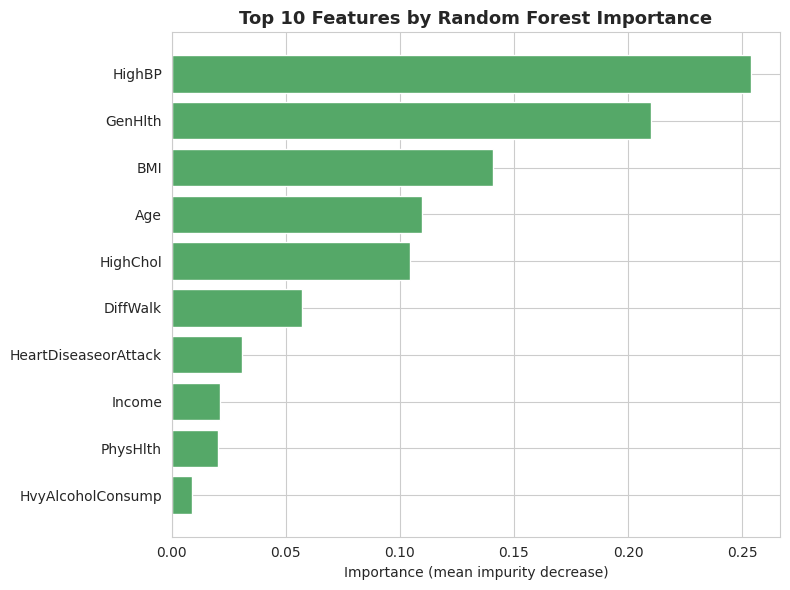

Spearman rank correlation between Random Forest importance and |Pearson r|: 0.9195 (p=3.854e-09)


In [35]:
fig, ax = plt.subplots(figsize=(8, 6))
top10 = importance_df_sorted.head(10)
ax.barh(top10.index[::-1], top10['RandomForest_Importance'][::-1], color='#55A868')
ax.set_title('Top 10 Features by Random Forest Importance', fontsize=13, fontweight='bold')
ax.set_xlabel('Importance (mean impurity decrease)')
plt.tight_layout()
plt.savefig('rf_feature_importance.png', dpi=150)
plt.show()

rank_corr, p_value = spearmanr(
    importance_df['RandomForest_Importance'], importance_df['Pearson_r'].abs()
)
print(f"Spearman rank correlation between Random Forest importance and |Pearson r|: "
      f"{rank_corr:.4f} (p={p_value:.4g})")


A high positive Spearman rank correlation indicates that the features the Random Forest
relies on most for splitting are largely the same features identified as most associated
with the target during EDA (`GenHlth`, `HighBP`, `BMI`, `HighChol`, `Age`), rather than the
model relying on a different, EDA-inconsistent set of features.

### 5.4b Explaining XGBoost with SHAP

Impurity-based importance (above) has two known weaknesses: it is biased towards features
with many distinct values (such as `BMI`), and it only says *how much* a feature is used,
not in *which direction* it pushes a prediction. SHAP (SHapley Additive exPlanations)
addresses both: for every individual prediction it splits the model's output into one
contribution per feature, and those contributions add up exactly to the prediction.
`TreeExplainer` computes these values exactly for tree ensembles. The explanation is run
on a random sample of 5,000 test-set rows; it explains the already-trained final model and
does not change any modelling decision.

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Mean |SHAP| per feature (XGBoost, top 10):
GenHlth              0.5098
HighBP               0.4604
Age                  0.3783
BMI                  0.3773
HighChol             0.2787
Sex                  0.1005
Income               0.0898
MentHlth             0.0721
CholCheck            0.0703
HvyAlcoholConsump    0.0622
dtype: float32

Spearman rank correlation, mean |SHAP| vs. |Pearson r|: 0.6870 (p=0.000581)
Share of total mean |SHAP| taken by HighBP: 18.0% (vs. 65.4% of XGBoost's built-in importance)


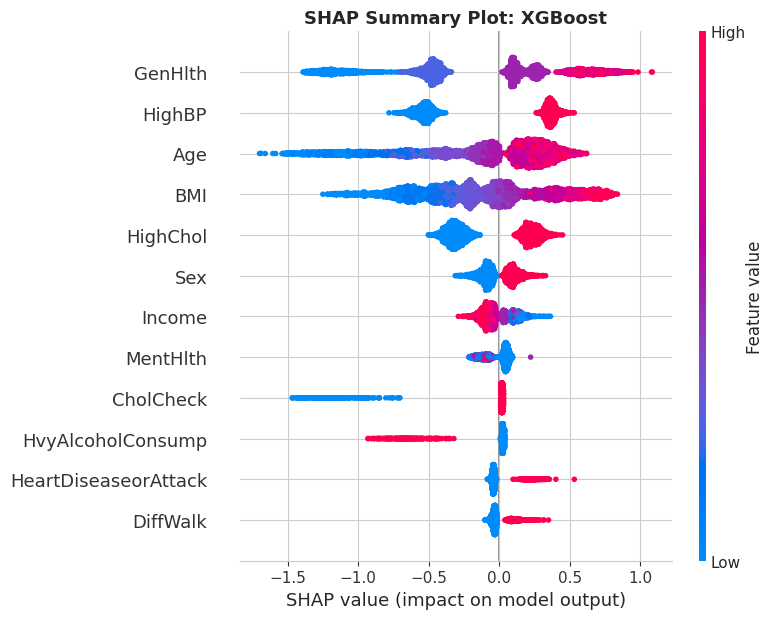

<Figure size 640x480 with 0 Axes>

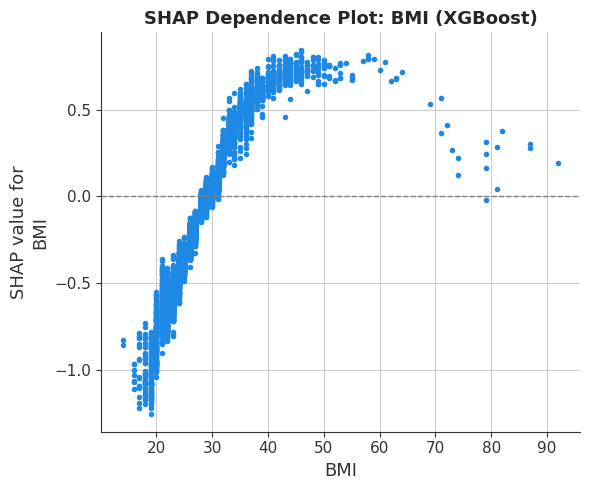

Lowest BMI at which the average SHAP contribution becomes positive: 29


In [36]:
import shap

shap_sample = X_test.sample(5000, random_state=42)
xgb_explainer = shap.TreeExplainer(xgb_model)
shap_values = xgb_explainer.shap_values(shap_sample)

# Global ranking: mean absolute SHAP value per feature
shap_importance = pd.Series(np.abs(shap_values).mean(axis=0), index=shap_sample.columns).sort_values(ascending=False)
print("Mean |SHAP| per feature (XGBoost, top 10):")
print(shap_importance.head(10).round(4))

shap_vs_pearson, shap_p = spearmanr(shap_importance.reindex(feature_cols), corr_with_target.reindex(feature_cols).abs())
print(f"\nSpearman rank correlation, mean |SHAP| vs. |Pearson r|: {shap_vs_pearson:.4f} (p={shap_p:.3g})")
print(f"Share of total mean |SHAP| taken by HighBP: {shap_importance['HighBP'] / shap_importance.sum():.1%} "
      f"(vs. {xgb_model.feature_importances_[feature_cols.index('HighBP')]:.1%} of XGBoost's built-in importance)")

plt.figure()
shap.summary_plot(shap_values, shap_sample, max_display=12, show=False)
plt.title('SHAP Summary Plot: XGBoost', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_summary_xgboost.png', dpi=150, bbox_inches='tight')
plt.show()

plt.figure()
shap.dependence_plot('BMI', shap_values, shap_sample, interaction_index=None, show=False)
plt.axhline(0, color='grey', linewidth=1, linestyle='--')
plt.title('SHAP Dependence Plot: BMI (XGBoost)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_dependence_bmi.png', dpi=150, bbox_inches='tight')
plt.show()

bmi_shap = pd.DataFrame({'BMI': shap_sample['BMI'].values, 'shap': shap_values[:, feature_cols.index('BMI')]})
crossing = bmi_shap.groupby('BMI')['shap'].mean()
print(f"Lowest BMI at which the average SHAP contribution becomes positive: {crossing[crossing > 0].index.min():.0f}")

### 5.5 Gaussian Naive Bayes

Section 3.1c proposed a reduced feature set for Naive Bayes on a priori statistical
grounds, but never tested whether it actually helps this specific model rather than being
assumed to. That choice is made properly here: 5-fold cross-validation, computed on the
training set only, compares GaussianNB on the full 21-feature set against the reduced
11-feature set from Section 3.1c. The test set is deliberately not used for this
comparison — using it here would be the same test-set leakage already avoided for the
ANN's architecture choice in Section 5.6a. The balanced `priors` are used in place of
`class_weight`, which this model does not support.

In [37]:
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_val_score

nb_full_cv_recall = cross_val_score(
    GaussianNB(priors=gnb_priors), X_train, y_train, cv=5, scoring='recall'
).mean()
nb_reduced_cv_recall = cross_val_score(
    GaussianNB(priors=gnb_priors), X_train[reduced_feature_set], y_train, cv=5, scoring='recall'
).mean()

print(f"GaussianNB 5-fold CV Recall on the full feature set (training set only): {nb_full_cv_recall:.4f}")
print(f"GaussianNB 5-fold CV Recall on the reduced feature set (training set only): {nb_reduced_cv_recall:.4f}")

if nb_full_cv_recall >= nb_reduced_cv_recall:
    NB_FEATURE_SET = 'full'
    nb_features = feature_cols
else:
    NB_FEATURE_SET = 'reduced'
    nb_features = reduced_feature_set

print(f"\nFeature set selected for Naive Bayes (by training-set CV Recall): '{NB_FEATURE_SET}' "
      f"({len(nb_features)} features)")


GaussianNB 5-fold CV Recall on the full feature set (training set only): 0.7272
GaussianNB 5-fold CV Recall on the reduced feature set (training set only): 0.6421

Feature set selected for Naive Bayes (by training-set CV Recall): 'full' (21 features)


### 5.5b Naive Bayes Assumption Check: Gaussian vs. Bernoulli

`GaussianNB` assumes each feature is normally distributed within each class. This is
violated to different degrees by the features in `reduced_feature_set`:
- Continuous features (e.g. `BMI`, `PhysHlth`) are skewed rather than normally distributed,
  a moderate violation.
- The 5 binary flag features remaining in `reduced_feature_set` (`HighBP`, `HighChol`,
  `HeartDiseaseorAttack`, `PhysActivity`, `DiffWalk`) take only two discrete values, so they
  cannot be normally distributed under any circumstance — a more severe violation than the
  feature-independence assumption discussed in Step 3.1c.

To check whether this specifically affects performance, `BernoulliNB` — which assumes
Bernoulli-distributed features, matching the actual distribution of the binary flags — is
trained on just those 5 binary features and compared against `GaussianNB` restricted to
the same 5 features. This isolates the effect of the distributional assumption from any effect
of the continuous features. Both models are compared with 5-fold stratified cross-validation
on the training set, as in Section 5.5, so the test set is not involved in this check.

In [38]:
from sklearn.naive_bayes import BernoulliNB
from sklearn.model_selection import cross_validate

nb_binary_features = [f for f in reduced_feature_set if f in binary_features]
print(f"Binary features used for this comparison: {nb_binary_features}")

nb_assumption_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
nb_assumption_results = {}
for nb_name, nb_candidate in [('GaussianNB', GaussianNB(priors=gnb_priors)),
                              ('BernoulliNB', BernoulliNB(class_prior=gnb_priors))]:
    cv_res = cross_validate(nb_candidate, X_train[nb_binary_features], y_train,
                            cv=nb_assumption_cv, scoring=['recall', 'f1'])
    nb_assumption_results[nb_name] = {
        'Recall (mean)': cv_res['test_recall'].mean(),
        'Recall (std)': cv_res['test_recall'].std(),
        'F1-Score (mean)': cv_res['test_f1'].mean()
    }

print("GaussianNB vs. BernoulliNB on the same binary features (5-fold CV, training set only):")
pd.DataFrame(nb_assumption_results).T.round(4)


Binary features used for this comparison: ['HighBP', 'HighChol', 'HeartDiseaseorAttack', 'PhysActivity', 'DiffWalk']


GaussianNB vs. BernoulliNB on the same binary features (5-fold CV, training set only):


,Recall (mean),Recall (std),F1-Score (mean)
GaussianNB,0.5311,0.0060,0.3911
BernoulliNB,0.6889,0.0051,0.4102


If `BernoulliNB` performs better than `GaussianNB` on this identical binary-only subset,
that difference is attributable specifically to the distributional assumption mismatch,
since both models see exactly the same features and the same independence assumption.

### 5.5c Does a log transformation help Gaussian Naive Bayes?

Section 3.2b found three strongly skewed features. Gaussian Naive Bayes assumes each feature
is normally distributed within each class, so it is the model most directly affected by
skew. The check below compares the raw and `log1p`-transformed versions of the skewed
features with 5-fold stratified cross-validation on the training set. `log1p` has no fitted
parameters, so applying it cannot leak information between folds.

**Decision rule, fixed before running:** adopt the transformation only if it improves mean
CV Recall by more than the larger of the two fold-to-fold standard deviations.

The final Naive Bayes model is fitted and evaluated on the test set only after this decision.

In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline

def make_nb_model(use_log):
    """GaussianNB with balanced priors, optionally applying log1p to the skewed features."""
    if not use_log:
        return GaussianNB(priors=gnb_priors)
    log_cols = [c for c in SKEWED_FEATURES if c in nb_features]
    log_step = ColumnTransformer([('log1p', FunctionTransformer(np.log1p), log_cols)],
                                 remainder='passthrough')
    return Pipeline([('log1p', log_step), ('nb', GaussianNB(priors=gnb_priors))])

nb_log_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
nb_log_results = {}
for label, use_log in [('Raw features', False), ('log1p on skewed features', True)]:
    res = cross_validate(make_nb_model(use_log), X_train[nb_features], y_train,
                         cv=nb_log_cv, scoring=['recall', 'precision', 'roc_auc'])
    nb_log_results[label] = {'Recall (mean)': res['test_recall'].mean(), 'Recall (std)': res['test_recall'].std(),
                             'Precision (mean)': res['test_precision'].mean(), 'ROC-AUC (mean)': res['test_roc_auc'].mean()}
nb_log_df = pd.DataFrame(nb_log_results).T
print("GaussianNB, raw vs. log1p-transformed skewed features (5-fold CV, training set only):")
print(nb_log_df.round(4))

gain = nb_log_df.loc['log1p on skewed features', 'Recall (mean)'] - nb_log_df.loc['Raw features', 'Recall (mean)']
noise = nb_log_df['Recall (std)'].max()
NB_USE_LOG = gain > noise
print(f"\nRecall gain = {gain:+.4f}; largest fold std = {noise:.4f} -> use log1p for Naive Bayes: {NB_USE_LOG}")

GaussianNB, raw vs. log1p-transformed skewed features (5-fold CV, training set only):
                          Recall (mean)  Recall (std)  Precision (mean)  \
Raw features                     0.7270        0.0054            0.2953   
log1p on skewed features         0.7481        0.0041            0.2945   

                          ROC-AUC (mean)  
Raw features                      0.7668  
log1p on skewed features          0.7709  

Recall gain = +0.0210; largest fold std = 0.0054 -> use log1p for Naive Bayes: True


In [40]:
X_train_nb = X_train[nb_features]
X_test_nb = X_test[nb_features]

# Final Naive Bayes model: uses the log1p decision made in Section 5.5c
nb_model = make_nb_model(NB_USE_LOG)
nb_model.fit(X_train_nb, y_train)

nb_pred = nb_model.predict(X_test_nb)
nb_proba = nb_model.predict_proba(X_test_nb)[:, 1]

evaluate_model('Naive Bayes', y_test, nb_pred, nb_proba)

--- Naive Bayes ---
              precision    recall  f1-score   support

 No Diabetes       0.94      0.68      0.79     38876
    Diabetes       0.30      0.76      0.43      7019

    accuracy                           0.69     45895
   macro avg       0.62      0.72      0.61     45895
weighted avg       0.84      0.69      0.73     45895



{'Accuracy': 0.6886371064386099,
 'Precision': 0.29727318351642223,
 'Recall': 0.7595099016953982,
 'F1-Score': 0.4273004168002565,
 'ROC-AUC': 0.7755418516181608,
 'PR-AUC': 0.3594328033128325}

### 5.6 Multilayer ANN (Deep Learning) — Architecture Ablation

Two architectures are compared:
- **Shallow:** 2 hidden layers (32 → 16 units) — a minimal multilayer network.
- **Deep:** 3 hidden layers (64 → 32 → 16 units) with `BatchNormalization` and `Dropout`
  after each of the first two layers — closer to what "Deep Learning" is intended to mean
  in the project brief, and with regularization to control overfitting from the added
  capacity.

**On avoiding test-set leakage in this comparison:** choosing between two architectures
based on their Recall on the test set, and then reporting that same test-set Recall as the
final result, would evaluate the selection and the final metric on the same data twice —
the reported number would no longer reflect performance on genuinely unseen data. To avoid
this, the training set is split further into an ANN-selection subset and a held-out
validation subset; architecture selection uses Recall on that validation subset only. The
winning architecture is then retrained on the **full** training set and evaluated on the
test set for the first and only time, in Section 5.6c.

In [41]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

def build_shallow_ann(input_dim, dropout_rate=0.0, learning_rate=0.001):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(32, activation='relu'),
        layers.Dense(16, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model

def build_deep_ann(input_dim, dropout_rate=0.3, learning_rate=0.001):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation='relu'), layers.BatchNormalization(), layers.Dropout(dropout_rate),
        layers.Dense(32, activation='relu'), layers.BatchNormalization(), layers.Dropout(dropout_rate),
        layers.Dense(16, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model

ANN_ARCHITECTURES = {'shallow': build_shallow_ann, 'deep': build_deep_ann}


I0000 00:00:1790638842.418796     121 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1790638843.639034     121 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


### 5.6a Architecture selection (on a validation split of the training set)

In [42]:
from sklearn.model_selection import train_test_split as _train_test_split_for_ann

X_ann_sel_train, X_ann_val, y_ann_sel_train, y_ann_val = _train_test_split_for_ann(
    X_train_scaled, y_train, test_size=0.15, stratify=y_train, random_state=42
)

ann_sel_class_weights = compute_class_weight(
    class_weight='balanced', classes=np.unique(y_ann_sel_train), y=y_ann_sel_train
)
ann_sel_class_weight_dict = dict(zip(np.unique(y_ann_sel_train).astype(int), ann_sel_class_weights))

print(f"ANN-selection training subset: {X_ann_sel_train.shape[0]} rows")
print(f"Held-out validation subset for architecture selection: {X_ann_val.shape[0]} rows")


ANN-selection training subset: 156042 rows
Held-out validation subset for architecture selection: 27537 rows


In [43]:
ablation_results = {}

for arch_name, build_fn in ANN_ARCHITECTURES.items():
    tf.random.set_seed(42)
    model = build_fn(X_ann_sel_train.shape[1])
    early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

    model.fit(
        X_ann_sel_train, y_ann_sel_train,
        validation_data=(X_ann_val, y_ann_val),
        epochs=30, batch_size=512,
        class_weight=ann_sel_class_weight_dict, callbacks=[early_stop], verbose=0
    )

    val_proba = model.predict(X_ann_val, verbose=0).ravel()
    val_pred = (val_proba >= 0.5).astype(int)

    ablation_results[arch_name] = {
        'Val Accuracy': accuracy_score(y_ann_val, val_pred),
        'Val Precision': precision_score(y_ann_val, val_pred),
        'Val Recall': recall_score(y_ann_val, val_pred),
        'Val F1-Score': f1_score(y_ann_val, val_pred),
        'Val ROC-AUC': roc_auc_score(y_ann_val, val_proba)
    }

pd.DataFrame(ablation_results).T.round(4)


,Val Accuracy,Val Precision,Val Recall,Val F1-Score,Val ROC-AUC
shallow,0.6958,0.3082,0.7942,0.4440,0.8173
deep,0.6931,0.3065,0.7968,0.4427,0.8145


In [44]:
ANN_ARCHITECTURE = max(ablation_results, key=lambda k: ablation_results[k]['Val Recall'])
print(f"Architecture selected (by validation-set Recall, not test-set Recall): "
      f"'{ANN_ARCHITECTURE}' (Val Recall = {ablation_results[ANN_ARCHITECTURE]['Val Recall']:.4f})")


Architecture selected (by validation-set Recall, not test-set Recall): 'deep' (Val Recall = 0.7968)


### 5.6b Hyperparameter Search (dropout rate, learning rate)

Decision Tree, Random Forest, and XGBoost were each tuned with a systematic search over
their hyperparameters (Sections 5.2-5.3b). For consistency, the same idea is applied to the
selected ANN architecture: a small grid over `dropout_rate` and `learning_rate` is
evaluated on the same held-out validation subset used for architecture selection above —
never the test set. The grid is kept deliberately small (9 combinations for the deep
architecture, 3 for the shallow one, which has no dropout layers) because, unlike the
scikit-learn models, each combination here requires a full training run rather than a
comparatively cheap tree fit.

In [45]:
if ANN_ARCHITECTURE == 'deep':
    ann_hp_grid = [
        {'dropout_rate': d, 'learning_rate': lr}
        for d in [0.2, 0.3, 0.4] for lr in [0.0005, 0.001, 0.002]
    ]
else:
    ann_hp_grid = [{'dropout_rate': 0.0, 'learning_rate': lr} for lr in [0.0005, 0.001, 0.002]]

ann_hp_results = []
for hp in ann_hp_grid:
    tf.random.set_seed(42)
    model = ANN_ARCHITECTURES[ANN_ARCHITECTURE](X_ann_sel_train.shape[1], **hp)
    early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
    model.fit(
        X_ann_sel_train, y_ann_sel_train,
        validation_data=(X_ann_val, y_ann_val),
        epochs=15, batch_size=512,
        class_weight=ann_sel_class_weight_dict, callbacks=[early_stop], verbose=0
    )
    val_proba = model.predict(X_ann_val, verbose=0).ravel()
    val_recall = recall_score(y_ann_val, (val_proba >= 0.5).astype(int))
    ann_hp_results.append({**hp, 'Val Recall': val_recall})

ann_hp_df = pd.DataFrame(ann_hp_results).sort_values('Val Recall', ascending=False)
ann_hp_df


,dropout_rate,learning_rate,Val Recall
4,0.3,0.0010,0.807217
8,0.4,0.0020,0.799145
3,0.3,0.0005,0.797009
2,0.2,0.0020,0.797009
0,0.2,0.0005,0.792260
6,0.4,0.0005,0.791548
1,0.2,0.0010,0.788936
7,0.4,0.0010,0.783951
5,0.3,0.0020,0.765907


In [46]:
best_hp_row = ann_hp_df.iloc[0]
ANN_BEST_HP = {'dropout_rate': best_hp_row['dropout_rate'], 'learning_rate': best_hp_row['learning_rate']}
print(f"Selected hyperparameters (by validation Recall): {ANN_BEST_HP} "
      f"(Val Recall = {best_hp_row['Val Recall']:.4f})")


Selected hyperparameters (by validation Recall): {'dropout_rate': np.float64(0.3), 'learning_rate': np.float64(0.001)} (Val Recall = 0.8072)


### 5.6b-2 Does a log transformation help the ANN?

The same `log1p` check is applied to the ANN, using the same selection/validation split as
Sections 5.6a and 5.6b and the selected architecture and hyperparameters. Because ANN
training is not fully deterministic, each variant is trained with three different random
seeds, which also shows how much validation Recall varies from seed to seed.

**Decision rule, fixed before running:** adopt the transformation only if the mean gain in
validation Recall is larger than the seed-to-seed standard deviation. The ANN in the rest of
this notebook uses untransformed inputs; this check tests whether that is justified.

In [47]:
X_ann_raw_train, X_ann_raw_val, _, _ = _train_test_split_for_ann(
    X_train, y_train, test_size=0.15, stratify=y_train, random_state=42
)  # same split as Section 5.6a (identical random_state and stratification)

def ann_inputs(use_log):
    tr, va = X_ann_raw_train.copy(), X_ann_raw_val.copy()
    if use_log:
        tr[SKEWED_FEATURES] = np.log1p(tr[SKEWED_FEATURES])
        va[SKEWED_FEATURES] = np.log1p(va[SKEWED_FEATURES])
    sc = StandardScaler().fit(tr[cols_to_scale])  # fitted on the selection subset only
    tr[cols_to_scale] = sc.transform(tr[cols_to_scale])
    va[cols_to_scale] = sc.transform(va[cols_to_scale])
    return tr, va

ann_log_rows = []
for use_log in [False, True]:
    tr, va = ann_inputs(use_log)
    for seed in [42, 7, 123]:
        tf.keras.utils.set_random_seed(seed)
        m = ANN_ARCHITECTURES[ANN_ARCHITECTURE](tr.shape[1], **ANN_BEST_HP)
        m.fit(tr, y_ann_sel_train, validation_data=(va, y_ann_val), epochs=30, batch_size=512,
              class_weight=ann_sel_class_weight_dict, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)])
        p = m.predict(va, verbose=0).ravel()
        ann_log_rows.append({'Inputs': 'log1p' if use_log else 'raw', 'Seed': seed,
                             'Val Recall': recall_score(y_ann_val, (p >= 0.5).astype(int)),
                             'Val ROC-AUC': roc_auc_score(y_ann_val, p)})
ann_log_df = pd.DataFrame(ann_log_rows)
print(ann_log_df.round(4).to_string(index=False))
ann_log_summary = ann_log_df.groupby('Inputs')[['Val Recall', 'Val ROC-AUC']].agg(['mean', 'std'])
print("\n", ann_log_summary.round(4))

ann_gain = ann_log_summary.loc['log1p', ('Val Recall', 'mean')] - ann_log_summary.loc['raw', ('Val Recall', 'mean')]
ann_noise = ann_log_summary[('Val Recall', 'std')].max()
ANN_USE_LOG = ann_gain > ann_noise
print(f"\nRecall gain = {ann_gain:+.4f}; seed-to-seed std = {ann_noise:.4f} -> use log1p for the ANN: {ANN_USE_LOG}")

Inputs  Seed  Val Recall  Val ROC-AUC
   raw    42      0.8015       0.8126
   raw     7      0.7740       0.8138
   raw   123      0.7887       0.8158
 log1p    42      0.8041       0.8139
 log1p     7      0.7635       0.8169
 log1p   123      0.7889       0.8169

        Val Recall         Val ROC-AUC        
             mean     std        mean     std
Inputs                                       
log1p      0.7855  0.0205      0.8159  0.0017
raw        0.7881  0.0138      0.8140  0.0016

Recall gain = -0.0025; seed-to-seed std = 0.0205 -> use log1p for the ANN: False


### 5.6c Retrain the selected architecture on the full training set

The winning architecture and hyperparameters are retrained from scratch on the complete
`X_train_scaled`/`y_train` (not just the selection subset), so the final model benefits
from all of the available training data rather than the reduced subset used only for the
architecture and hyperparameter search above.

In [48]:
tf.random.set_seed(42)
ann_model = ANN_ARCHITECTURES[ANN_ARCHITECTURE](X_train_scaled.shape[1], **ANN_BEST_HP)
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history = ann_model.fit(
    X_train_scaled, y_train,
    validation_split=0.1, epochs=30, batch_size=512,
    class_weight=class_weight_dict, callbacks=[early_stop], verbose=2
)


Epoch 1/30


323/323 - 2s - 7ms/step - accuracy: 0.6759 - loss: 0.5848 - val_accuracy: 0.6740 - val_loss: 0.5595


Epoch 2/30


323/323 - 1s - 3ms/step - accuracy: 0.6865 - loss: 0.5444 - val_accuracy: 0.6796 - val_loss: 0.5508


Epoch 3/30


323/323 - 1s - 4ms/step - accuracy: 0.6906 - loss: 0.5373 - val_accuracy: 0.6802 - val_loss: 0.5468


... (10 outputs left out)

Epoch 9/30


323/323 - 1s - 4ms/step - accuracy: 0.6961 - loss: 0.5298 - val_accuracy: 0.7017 - val_loss: 0.5306


Epoch 10/30


323/323 - 1s - 3ms/step - accuracy: 0.6979 - loss: 0.5277 - val_accuracy: 0.7017 - val_loss: 0.5290


### 5.6d Evaluate on the test set (first and only use of the test set for the ANN)

In [49]:
ann_proba = ann_model.predict(X_test_scaled, verbose=0).ravel()
ann_pred = (ann_proba >= 0.5).astype(int)

evaluate_model('ANN', y_test, ann_pred, ann_proba)


--- ANN ---
              precision    recall  f1-score   support

 No Diabetes       0.95      0.68      0.79     38876
    Diabetes       0.31      0.81      0.45      7019

    accuracy                           0.70     45895
   macro avg       0.63      0.74      0.62     45895
weighted avg       0.85      0.70      0.74     45895



{'Accuracy': 0.6964810981588409,
 'Precision': 0.3105641138095499,
 'Recall': 0.8070950277817353,
 'F1-Score': 0.448535233570863,
 'ROC-AUC': 0.8172188119290693,
 'PR-AUC': 0.4369476024842947}

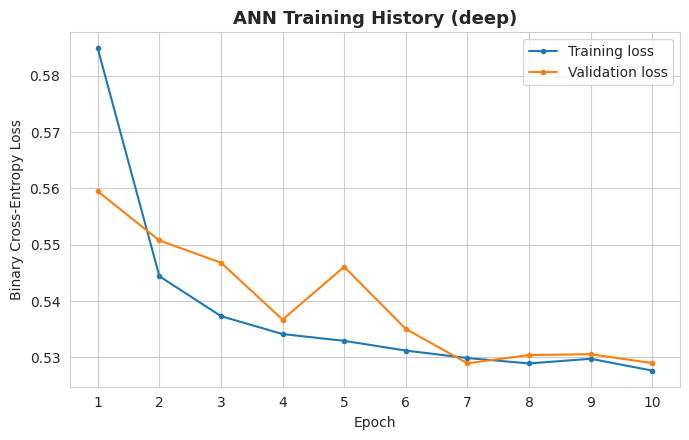

In [50]:
# Training/validation loss curve for the selected architecture
epochs = range(1, len(history.history['loss']) + 1)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(epochs, history.history['loss'], marker='o', markersize=3, label='Training loss')
ax.plot(epochs, history.history['val_loss'], marker='o', markersize=3, label='Validation loss')
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_title(f'ANN Training History ({ANN_ARCHITECTURE})', fontsize=13, fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Binary Cross-Entropy Loss')
ax.legend()
plt.tight_layout()
plt.savefig('ann_training_history.png', dpi=150)
plt.show()


### 5.6e Closing the Loop: Does the Reduced Feature Set Help the Other Models?

Section 3.1c identified 10 features as having a negligible effect on the target and built
`reduced_feature_set`. Section 5.5 already tested, properly via training-set cross-validation,
whether that set actually helps the model it was proposed for (Naive Bayes). The remaining
question is the other direction: does removing those 10 features help the models that were
**not** built around the reduced set? Random Forest, XGBoost, and the ANN are each re-trained
on `reduced_feature_set` instead of the full feature set, using the tuned
hyperparameters/architecture already selected for each, to check.

**Scope of this check:** it reports test-set Recall as a post-hoc diagnostic only. No model
is switched to the reduced set as a result of it, so it does not feed back into any
modelling decision.

In [51]:
feature_set_comparison = {}

rf_reduced_check = RandomForestClassifier(**rf_search.best_params_, class_weight='balanced', random_state=42, n_jobs=-1)
rf_reduced_check.fit(X_train[reduced_feature_set], y_train)
rf_reduced_pred = rf_reduced_check.predict(X_test[reduced_feature_set])
feature_set_comparison['Random Forest'] = {
    'Full (21 feat.) Recall': recall_score(y_test, rf_pred),
    'Reduced (11 feat.) Recall': recall_score(y_test, rf_reduced_pred)
}

xgb_reduced_check = XGBClassifier(**xgb_search.best_params_, scale_pos_weight=scale_pos_weight,
                                   random_state=42, eval_metric='logloss', n_jobs=-1)
xgb_reduced_check.fit(X_train[reduced_feature_set], y_train)
xgb_reduced_pred = xgb_reduced_check.predict(X_test[reduced_feature_set])
feature_set_comparison['XGBoost'] = {
    'Full (21 feat.) Recall': recall_score(y_test, xgb_pred),
    'Reduced (11 feat.) Recall': recall_score(y_test, xgb_reduced_pred)
}

reduced_cols_to_scale = [c for c in cols_to_scale if c in reduced_feature_set]
scaler_reduced = StandardScaler()
X_train_reduced_scaled = X_train[reduced_feature_set].copy()
X_test_reduced_scaled = X_test[reduced_feature_set].copy()
X_train_reduced_scaled[reduced_cols_to_scale] = scaler_reduced.fit_transform(X_train[reduced_cols_to_scale])
X_test_reduced_scaled[reduced_cols_to_scale] = scaler_reduced.transform(X_test[reduced_cols_to_scale])

tf.random.set_seed(42)
ann_reduced_check = ANN_ARCHITECTURES[ANN_ARCHITECTURE](X_train_reduced_scaled.shape[1], **ANN_BEST_HP)
es_reduced = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
ann_reduced_check.fit(X_train_reduced_scaled, y_train, validation_split=0.1, epochs=30, batch_size=512,
                       class_weight=class_weight_dict, callbacks=[es_reduced], verbose=0)
ann_reduced_pred = (ann_reduced_check.predict(X_test_reduced_scaled, verbose=0).ravel() >= 0.5).astype(int)
feature_set_comparison['ANN'] = {
    'Full (21 feat.) Recall': recall_score(y_test, ann_pred),
    'Reduced (11 feat.) Recall': recall_score(y_test, ann_reduced_pred)
}

pd.DataFrame(feature_set_comparison).T.round(4)


,Full (21 feat.) Recall,Reduced (11 feat.) Recall
Random Forest,0.7846,0.7809
XGBoost,0.7938,0.7836
ANN,0.8071,0.7937


If the full feature set gives equal or better Recall for Random Forest, XGBoost, and the
ANN, this confirms these models' internal feature weighting (trees) or learned
representations (ANN) already handle the negligible-effect features without needing them
removed — unlike Naive Bayes, where Section 5.5 found the feature-set choice does make a
measurable difference to the model's Recall.

### 5.7 Model comparison

In [52]:
comparison_df = pd.DataFrame(results).T
comparison_df = comparison_df[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC']]
comparison_df = comparison_df.round(4).sort_values('Recall', ascending=False)

comparison_df


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
ANN,0.6965,0.3106,0.8071,0.4485,0.8172,0.4369
XGBoost,0.7048,0.3152,0.7938,0.4513,0.8185,0.4456
Random Forest,0.7064,0.3152,0.7846,0.4497,0.8149,0.4387
Decision Tree,0.6871,0.2995,0.7812,0.4330,0.8014,0.4077
Naive Bayes,0.6886,0.2973,0.7595,0.4273,0.7755,0.3594
Baseline (Dummy),0.7426,0.1578,0.1574,0.1576,0.5029,0.1537


**On Recall at a fixed 0.5 threshold vs. ranking quality:** Recall computed at the
default 0.5 threshold depends on how a model's predicted probabilities are positioned
relative to that cut-off, not only on how well the model ranks positive cases ahead of
negative ones. Two models with very similar ROC-AUC (which measures ranking quality
independent of any threshold) and PR-AUC (the ranking-quality analogue that focuses on
the positive class) could show a Recall gap at 0.5 simply because one model's
probabilities are shifted, not because it ranks cases better. ROC-AUC and PR-AUC are
therefore included above for every model, not only the one ultimately selected, so this
can be checked directly rather than inferred from Recall alone.

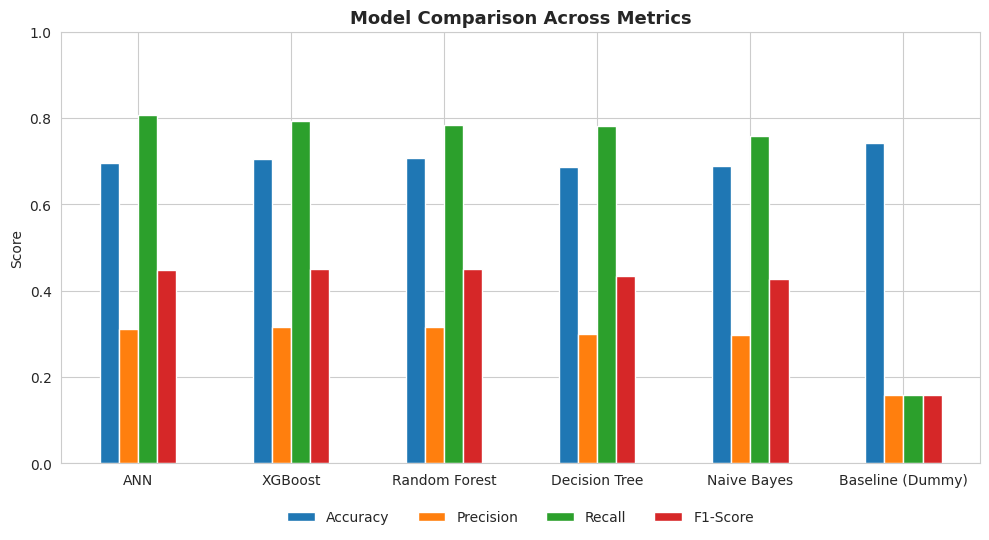

In [53]:
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
ax = comparison_df[metrics_to_plot].plot(kind='bar', figsize=(10, 5.5))
ax.set_title('Model Comparison Across Metrics', fontsize=13, fontweight='bold')
ax.set_ylabel('Score')
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
# Legend placed below the plot so it never covers any bars
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=4, frameon=False)
plt.tight_layout()
plt.savefig('model_comparison_bar_chart.png', dpi=150)
plt.show()


### 5.8 Confusion matrices

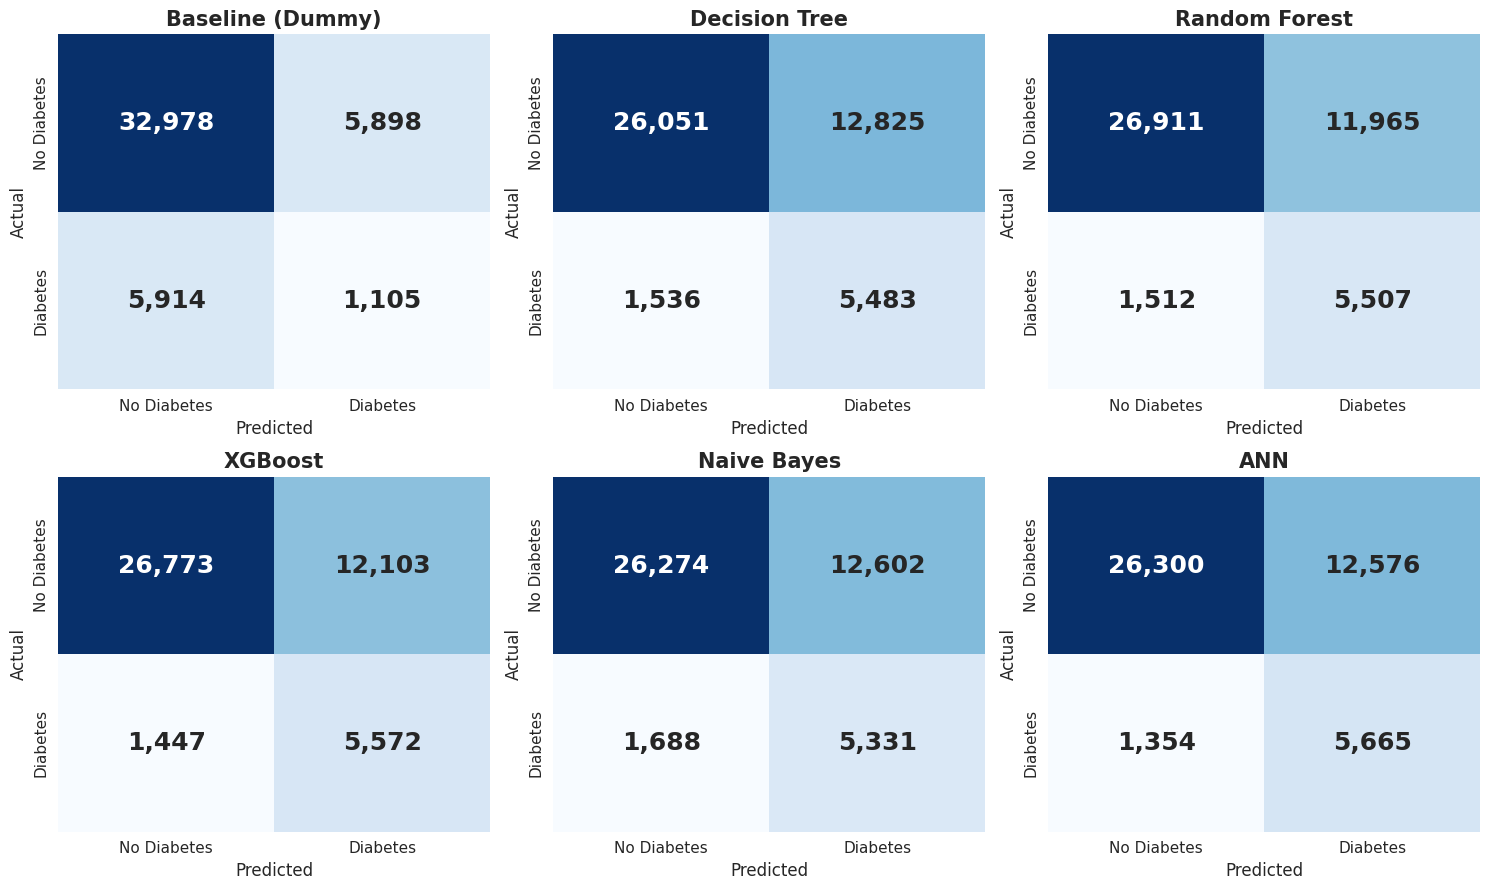

In [54]:
import math

n_models = len(confusion_matrices)
ncols = 3
nrows = math.ceil(n_models / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.5 * nrows))
axes_flat = axes.ravel()

for ax, (name, cm) in zip(axes_flat, confusion_matrices.items()):
    sns.heatmap(
        cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax,
        annot_kws={'size': 18, 'weight': 'bold'},
        xticklabels=['No Diabetes', 'Diabetes'],
        yticklabels=['No Diabetes', 'Diabetes']
    )
    ax.set_title(name, fontsize=15, fontweight='bold')
    ax.set_xlabel('Predicted', fontsize=12)
    ax.set_ylabel('Actual', fontsize=12)
    ax.tick_params(labelsize=11)

# Hide any unused subplot positions
for ax in axes_flat[n_models:]:
    ax.axis('off')

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150)
plt.show()


### 5.9 Cross-Validation (robustness check)

A single train/test split gives one metric value per model, which does not indicate how
much that value would vary on a different split of the same data — this matters
particularly for the ANN, whose CPU-based training is not fully deterministic even with a
fixed random seed. **10-fold Stratified Cross-Validation** is run on the training set for
all five models, refitting each model from scratch on each fold, to obtain a mean and
standard deviation for each metric instead of a single point estimate. Each model uses the
same hyperparameters/architecture selected earlier (`dt_search.best_params_`,
`rf_search.best_params_`, `xgb_search.best_params_`, and `ANN_ARCHITECTURE`), so this is a
robustness check on the already-tuned configurations, not a second, separate model.

**10 folds instead of 5:** a paired statistical test run later on only 5 fold-level values
has very limited power (Section 5.10 discusses this in more detail) — doubling the number
of folds to 10 gives that test more values to work with, at roughly double the
cross-validation runtime.

In [55]:
from sklearn.model_selection import StratifiedKFold

N_SPLITS = 10
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

X_cv = X_train.reset_index(drop=True)
y_cv = y_train.reset_index(drop=True)
X_cv_scaled = X_train_scaled.reset_index(drop=True)
X_cv_nb = X_train[nb_features].reset_index(drop=True)

cv_metrics = {name: {'Accuracy': [], 'Precision': [], 'Recall': [], 'F1-Score': [], 'ROC-AUC': [], 'PR-AUC': []}
              for name in ['Decision Tree', 'Random Forest', 'XGBoost', 'Naive Bayes', 'ANN']}

# Out-of-fold predictions: prediction for row i is made by the fold in which row i was
# held out, so it is a genuinely unseen-data prediction for every row in the training set.
# These are used in Section 5.11 to choose the classification threshold WITHOUT touching
# the test set, instead of the test set itself.
oof_proba = {name: np.zeros(len(X_cv)) for name in cv_metrics}

def record_fold(name, y_true, y_pred, y_proba):
    cv_metrics[name]['Accuracy'].append(accuracy_score(y_true, y_pred))
    cv_metrics[name]['Precision'].append(precision_score(y_true, y_pred, pos_label=1))
    cv_metrics[name]['Recall'].append(recall_score(y_true, y_pred, pos_label=1))
    cv_metrics[name]['F1-Score'].append(f1_score(y_true, y_pred, pos_label=1))
    cv_metrics[name]['ROC-AUC'].append(roc_auc_score(y_true, y_proba))
    cv_metrics[name]['PR-AUC'].append(average_precision_score(y_true, y_proba))

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_cv, y_cv), start=1):
    y_tr, y_val = y_cv.iloc[tr_idx], y_cv.iloc[val_idx]

    dt_cv = DecisionTreeClassifier(class_weight='balanced', random_state=42, **dt_search.best_params_)
    dt_cv.fit(X_cv.iloc[tr_idx], y_tr)
    dt_val_proba = dt_cv.predict_proba(X_cv.iloc[val_idx])[:, 1]
    record_fold('Decision Tree', y_val, dt_cv.predict(X_cv.iloc[val_idx]), dt_val_proba)
    oof_proba['Decision Tree'][val_idx] = dt_val_proba

    rf_cv = RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1,
                                    **rf_search.best_params_)
    rf_cv.fit(X_cv.iloc[tr_idx], y_tr)
    rf_val_proba = rf_cv.predict_proba(X_cv.iloc[val_idx])[:, 1]
    record_fold('Random Forest', y_val, rf_cv.predict(X_cv.iloc[val_idx]), rf_val_proba)
    oof_proba['Random Forest'][val_idx] = rf_val_proba

    fold_scale_pos_weight = (y_tr == 0).sum() / (y_tr == 1).sum()
    xgb_cv = XGBClassifier(scale_pos_weight=fold_scale_pos_weight, random_state=42,
                            eval_metric='logloss', n_jobs=-1, **xgb_search.best_params_)
    xgb_cv.fit(X_cv.iloc[tr_idx], y_tr)
    xgb_val_proba = xgb_cv.predict_proba(X_cv.iloc[val_idx])[:, 1]
    record_fold('XGBoost', y_val, xgb_cv.predict(X_cv.iloc[val_idx]), xgb_val_proba)
    oof_proba['XGBoost'][val_idx] = xgb_val_proba

    nb_cv = make_nb_model(NB_USE_LOG)
    nb_cv.fit(X_cv_nb.iloc[tr_idx], y_tr)
    nb_val_proba = nb_cv.predict_proba(X_cv_nb.iloc[val_idx])[:, 1]
    record_fold('Naive Bayes', y_val, nb_cv.predict(X_cv_nb.iloc[val_idx]), nb_val_proba)
    oof_proba['Naive Bayes'][val_idx] = nb_val_proba

    fold_class_weights = compute_class_weight('balanced', classes=np.unique(y_tr), y=y_tr)
    fold_class_weight_dict = dict(zip(np.unique(y_tr).astype(int), fold_class_weights))

    # Refit the scaler inside this fold, on this fold's training rows only, rather than
    # reusing X_cv_scaled (which was scaled once using statistics from the *entire*
    # training set). Reusing it would let each fold's scaling see its own validation
    # rows' distribution — a smaller-scale version of the same leakage this notebook
    # avoids elsewhere.
    fold_scaler = StandardScaler()
    X_fold_train_scaled = X_cv.iloc[tr_idx].copy()
    X_fold_val_scaled = X_cv.iloc[val_idx].copy()
    X_fold_train_scaled[cols_to_scale] = fold_scaler.fit_transform(X_cv.iloc[tr_idx][cols_to_scale])
    X_fold_val_scaled[cols_to_scale] = fold_scaler.transform(X_cv.iloc[val_idx][cols_to_scale])

    tf.random.set_seed(42)
    ann_cv = ANN_ARCHITECTURES[ANN_ARCHITECTURE](X_fold_train_scaled.shape[1], **ANN_BEST_HP)
    ann_cv.fit(X_fold_train_scaled, y_tr, validation_split=0.1, epochs=30,
               batch_size=512, class_weight=fold_class_weight_dict,
               callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=3,
                                                          restore_best_weights=True)],
               verbose=0)
    ann_val_proba = ann_cv.predict(X_fold_val_scaled, verbose=0).ravel()
    record_fold('ANN', y_val, (ann_val_proba >= 0.5).astype(int), ann_val_proba)
    oof_proba['ANN'][val_idx] = ann_val_proba

    print(f"Fold {fold}/{N_SPLITS} complete")


Fold 1/10 complete


Fold 2/10 complete


Fold 3/10 complete


Fold 4/10 complete


Fold 5/10 complete


Fold 6/10 complete


Fold 7/10 complete


Fold 8/10 complete


Fold 9/10 complete


Fold 10/10 complete


In [56]:
cv_summary_rows = []
for name, metric_dict in cv_metrics.items():
    row = {'Model': name}
    for metric_name, values in metric_dict.items():
        row[f'{metric_name}_mean'] = np.mean(values)
        row[f'{metric_name}_std'] = np.std(values)
    cv_summary_rows.append(row)

cv_summary_df = pd.DataFrame(cv_summary_rows).set_index('Model')
cv_summary_df = cv_summary_df.round(4)

cv_summary_df[['Accuracy_mean', 'Accuracy_std', 'Precision_mean', 'Precision_std',
               'Recall_mean', 'Recall_std', 'F1-Score_mean', 'F1-Score_std',
               'ROC-AUC_mean', 'ROC-AUC_std', 'PR-AUC_mean', 'PR-AUC_std']]


,Accuracy_mean,Accuracy_std,Precision_mean,Precision_std,Recall_mean,Recall_std,F1-Score_mean,F1-Score_std,ROC-AUC_mean,ROC-AUC_std,PR-AUC_mean,PR-AUC_std
Model,,,,,,,,,,,,
Decision Tree,0.6825,0.0090,0.2958,0.0052,0.7779,0.0138,0.4285,0.0045,0.7964,0.0024,0.3982,0.0082
Random Forest,0.7065,0.0027,0.3138,0.0026,0.7741,0.0072,0.4465,0.0034,0.8097,0.0023,0.4240,0.0093
XGBoost,0.7060,0.0035,0.3149,0.0032,0.7845,0.0067,0.4494,0.0038,0.8150,0.0024,0.4323,0.0089
Naive Bayes,0.6874,0.0031,0.2945,0.0027,0.7480,0.0058,0.4226,0.0033,0.7709,0.0036,0.3510,0.0057
ANN,0.6997,0.0103,0.3110,0.0069,0.7912,0.0118,0.4464,0.0062,0.8128,0.0024,0.4253,0.0071


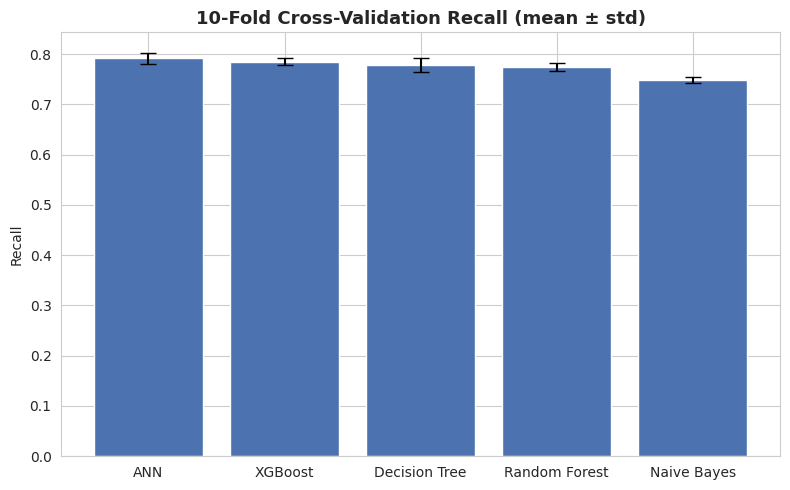

In [57]:
fig, ax = plt.subplots(figsize=(8, 5))
models_order = cv_summary_df['Recall_mean'].sort_values(ascending=False).index

ax.bar(models_order, cv_summary_df.loc[models_order, 'Recall_mean'],
       yerr=cv_summary_df.loc[models_order, 'Recall_std'], capsize=6, color='#4C72B0')
ax.set_title(f'{N_SPLITS}-Fold Cross-Validation Recall (mean ± std)', fontsize=13, fontweight='bold')
ax.set_ylabel('Recall')
plt.tight_layout()
plt.savefig('cv_recall_mean_std.png', dpi=150)
plt.show()


### 5.10 Final Model Selection

In a medical screening context, a false negative (an actual diabetic case predicted as
"no diabetes") means the person is not flagged for follow-up testing or treatment, while a
false positive (a healthy case predicted as "diabetes") only leads to an unnecessary follow-up
check. The cost of the two error types is not symmetric, so **Recall** on the positive class
is set as the priority metric.

The selection below uses the cross-validation mean Recall from Section 5.9 rather than the
single test-set Recall from Section 5.7, since the mean across folds is less sensitive to
the variance of any one split or any one training run (particularly relevant for the ANN,
which is not fully deterministic on CPU). Whether the top-ranked model is meaningfully
better than the others is checked with a **paired Wilcoxon signed-rank test** on the
per-fold Recall values, rather than an informal "within one standard deviation" rule.

**Two limitations of this test, stated plainly rather than glossed over:**

- **The p-value has a floor at this sample size.** With `N_SPLITS` = 10 paired
  observations and no ties, the smallest p-value the exact Wilcoxon signed-rank test can
  ever return is 2/2¹⁰ ≈ 0.00195 (rounds to 0.0020) — the value obtained only when one
  model wins every single fold. A result of p = 0.0020 for any comparison below
  therefore indicates that the top model won all 10 folds against that competitor; it is not a
  "more significant than usual" result on a continuous scale, since the test cannot report
  anything smaller here regardless of how large the true effect is.
- **CV folds are not independent samples.** Each pair of folds shares most of its training
  data (any two 10-fold training sets overlap in roughly 8/9 of their rows), which violates
  the independence assumption behind ordinary paired tests and makes them anti-conservative
  — they tend to report smaller p-values than are actually justified (Dietterich, 1998).
  The corrected resampled t-test (Nadeau & Bengio, 2003) adjusts for this by inflating the
  variance term to account for the overlap, and is applied in Section 5.10a below as a more
  defensible alternative to treating the Wilcoxon result at face value.

Section 5.10b adds a further, independent check using the test set directly (a bootstrap),
which does not share the CV-non-independence issue, to see whether it reaches a similar
conclusion.

In [58]:
from scipy.stats import wilcoxon

PRIORITY_METRIC = 'Recall'

ranked = cv_summary_df[[f'{PRIORITY_METRIC}_mean', f'{PRIORITY_METRIC}_std']].sort_values(
    f'{PRIORITY_METRIC}_mean', ascending=False
)
print(f"Models ranked by mean {PRIORITY_METRIC} ({N_SPLITS}-fold CV):")
print(ranked)

top_model = ranked.index[0]
top_mean, top_std = ranked.iloc[0]
print(f"\nTop model by mean {PRIORITY_METRIC}: {top_model} ({top_mean:.4f} ± {top_std:.4f})")

print(f"\nPaired Wilcoxon signed-rank test ({top_model} vs. each other model, "
      f"per-fold {PRIORITY_METRIC} values, n={N_SPLITS} folds):")

not_significantly_different = []
for name in ranked.index[1:]:
    top_scores = cv_metrics[top_model][PRIORITY_METRIC]
    other_scores = cv_metrics[name][PRIORITY_METRIC]
    stat, p_value = wilcoxon(top_scores, other_scores)
    verdict = "no significant difference" if p_value >= 0.05 else "significant difference"
    print(f"  {top_model} vs {name}: p = {p_value:.4f} -> {verdict} (alpha=0.05)")
    if p_value >= 0.05:
        not_significantly_different.append(name)

if not_significantly_different:
    print(f"\nNot significantly different from {top_model} on {PRIORITY_METRIC} at n={N_SPLITS} folds: "
          f"{not_significantly_different} (see small-sample caveat above)")
else:
    print(f"\n{top_model} is significantly better than every other model on {PRIORITY_METRIC} "
          f"at the 0.05 level, despite the small number of folds.")


Models ranked by mean Recall (10-fold CV):
               Recall_mean  Recall_std
Model                                 
ANN                 0.7912      0.0118
XGBoost             0.7845      0.0067
Decision Tree       0.7779      0.0138
Random Forest       0.7741      0.0072
Naive Bayes         0.7480      0.0058

Top model by mean Recall: ANN (0.7912 ± 0.0118)

Paired Wilcoxon signed-rank test (ANN vs. each other model, per-fold Recall values, n=10 folds):
  ANN vs XGBoost: p = 0.2852 -> no significant difference (alpha=0.05)
  ANN vs Decision Tree: p = 0.0371 -> significant difference (alpha=0.05)
  ANN vs Random Forest: p = 0.0059 -> significant difference (alpha=0.05)
  ANN vs Naive Bayes: p = 0.0020 -> significant difference (alpha=0.05)

Not significantly different from ANN on Recall at n=10 folds: ['XGBoost'] (see small-sample caveat above)


### 5.10a Corrected Resampled t-Test (Nadeau & Bengio, 2003)

This test targets the CV non-independence problem directly: given the per-fold Recall
differences between the top model and a competitor, it computes an ordinary paired t-statistic
but inflates the variance estimate by a factor of (1/k + n₂/n₁), where k is the number of
folds and n₂/n₁ is the ratio of validation-fold size to training-fold size (1/9 for 10-fold
CV). This correction is specifically designed for the overlapping-training-data situation
that makes the plain Wilcoxon/t-test overconfident, at the cost of a wider confidence
interval and a less extreme p-value.

In [59]:
from scipy import stats as _stats

def nadeau_bengio_test(scores_a, scores_b, k, n_test_ratio=1 / (10 - 1)):
    diffs = np.array(scores_a) - np.array(scores_b)
    mean_diff = diffs.mean()
    var_diff = diffs.var(ddof=1)
    if var_diff == 0:
        return np.inf if mean_diff != 0 else 0.0, 0.0 if mean_diff != 0 else 1.0
    corrected_variance = var_diff * (1 / k + n_test_ratio)
    t_stat = mean_diff / np.sqrt(corrected_variance)
    p_value = 2 * (1 - _stats.t.cdf(abs(t_stat), df=k - 1))
    return t_stat, p_value

print(f"Corrected resampled t-test ({top_model} vs. each other model, per-fold {PRIORITY_METRIC} "
      f"values, n={N_SPLITS} folds, variance inflated for CV-fold overlap):")

nb_not_significant = []
for name in ranked.index[1:]:
    t_stat, p_val = nadeau_bengio_test(
        cv_metrics[top_model][PRIORITY_METRIC], cv_metrics[name][PRIORITY_METRIC], k=N_SPLITS
    )
    verdict = "no significant difference" if p_val >= 0.05 else "significant difference"
    print(f"  {top_model} vs {name}: t = {t_stat:.3f}, p = {p_val:.4f} -> {verdict} (alpha=0.05)")
    if p_val >= 0.05:
        nb_not_significant.append(name)

if nb_not_significant:
    print(f"\nUnder the corrected test, not significantly different from {top_model}: {nb_not_significant}")
else:
    print(f"\n{top_model} remains significantly better than every other model under the "
          f"corrected test, despite its wider, more conservative confidence interval.")


Corrected resampled t-test (ANN vs. each other model, per-fold Recall values, n=10 folds, variance inflated for CV-fold overlap):
  ANN vs XGBoost: t = 1.045, p = 0.3233 -> no significant difference (alpha=0.05)
  ANN vs Decision Tree: t = 1.819, p = 0.1022 -> no significant difference (alpha=0.05)
  ANN vs Random Forest: t = 3.143, p = 0.0119 -> significant difference (alpha=0.05)
  ANN vs Naive Bayes: t = 7.488, p = 0.0000 -> significant difference (alpha=0.05)

Under the corrected test, not significantly different from ANN: ['XGBoost', 'Decision Tree']


### 5.10b Bootstrap Confidence Interval (higher-power check)

The Wilcoxon test above has only 10 paired observations to work with. A **paired
bootstrap** on the test set gives a much larger effective sample: the test set
(45,895 rows) is resampled with replacement 1,000 times, and the Recall difference between
the top model and each other model is recomputed on every resample using each model's
existing test-set predictions (no retraining). This produces a 95% confidence interval for
the true Recall difference and a bootstrap p-value, with far more statistical power than
the 10-fold test above, at the cost of measuring variability from a single test set
rather than across different data splits — the two checks are complementary, not
interchangeable.

In [60]:
test_predictions = {
    'Decision Tree': (dt_pred, dt_proba),
    'Random Forest': (rf_pred, rf_proba),
    'XGBoost': (xgb_pred, xgb_proba),
    'Naive Bayes': (nb_pred, nb_proba),
    'ANN': (ann_pred, ann_proba)
}

N_BOOTSTRAP = 1000
rng = np.random.RandomState(42)
y_test_arr = y_test.values
n_test = len(y_test_arr)

top_pred_arr = np.asarray(test_predictions[top_model][0])

print(f"Paired bootstrap on the test set ({n_test} rows, {N_BOOTSTRAP} resamples), "
      f"comparing {top_model} against each other model on Recall:")

bootstrap_not_significant = []
for name in ranked.index[1:]:
    other_pred_arr = np.asarray(test_predictions[name][0])

    diffs = np.empty(N_BOOTSTRAP)
    for b in range(N_BOOTSTRAP):
        idx = rng.randint(0, n_test, n_test)
        y_b = y_test_arr[idx]
        top_recall_b = recall_score(y_b, top_pred_arr[idx], zero_division=0)
        other_recall_b = recall_score(y_b, other_pred_arr[idx], zero_division=0)
        diffs[b] = top_recall_b - other_recall_b

    ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])
    p_value_boot = min(2 * min((diffs <= 0).mean(), (diffs >= 0).mean()), 1.0)
    verdict = "no significant difference" if p_value_boot >= 0.05 else "significant difference"

    print(f"  {top_model} vs {name}: mean Recall diff = {diffs.mean():.4f}, "
          f"95% CI = [{ci_low:.4f}, {ci_high:.4f}], bootstrap p ≈ {p_value_boot:.4f} -> {verdict}")
    if p_value_boot >= 0.05:
        bootstrap_not_significant.append(name)

if bootstrap_not_significant:
    print(f"\nNot significantly different from {top_model} on {PRIORITY_METRIC} "
          f"(bootstrap, n={N_BOOTSTRAP}): {bootstrap_not_significant}")
else:
    print(f"\n{top_model} is significantly better than every other model on {PRIORITY_METRIC} "
          f"at the 0.05 level (bootstrap, n={N_BOOTSTRAP}).")


Paired bootstrap on the test set (45895 rows, 1000 resamples), comparing ANN against each other model on Recall:


  ANN vs XGBoost: mean Recall diff = 0.0132, 95% CI = [0.0079, 0.0186], bootstrap p ≈ 0.0000 -> significant difference


  ANN vs Decision Tree: mean Recall diff = 0.0259, 95% CI = [0.0192, 0.0327], bootstrap p ≈ 0.0000 -> significant difference


  ANN vs Random Forest: mean Recall diff = 0.0226, 95% CI = [0.0171, 0.0277], bootstrap p ≈ 0.0000 -> significant difference


  ANN vs Naive Bayes: mean Recall diff = 0.0475, 95% CI = [0.0392, 0.0565], bootstrap p ≈ 0.0000 -> significant difference

ANN is significantly better than every other model on Recall at the 0.05 level (bootstrap, n=1000).


### 5.11 Threshold Tuning for the Selected Model

All models above were evaluated using the default 0.5 classification threshold. Given that
Recall on the positive class was set as the priority metric in Section 5.10, the decision
threshold for the selected model is tuned explicitly using the precision-recall trade-off,
rather than leaving the default threshold in place.

**Choosing the threshold without touching the test set:** `precision_recall_curve` needs a
set of predictions with known true labels to trace out the trade-off. Using the test set's
own predictions for this — as an earlier version of this notebook did — would mean the test
set is used twice: once to pick the threshold, and again to report the resulting metrics,
which is the same double-dipping this notebook avoids everywhere else. Instead, the
out-of-fold (OOF) predictions collected during the Section 5.9 cross-validation are used:
for every row in the training set, `oof_proba[top_model]` holds a prediction made by a model
that had that specific row held out at the time, so it is a genuinely unseen-data prediction
without needing the test set at all. The threshold is chosen on `y_train`/`oof_proba`, and
only then applied once to the test set to report final metrics.

In [61]:
from sklearn.metrics import precision_recall_curve

model_test_lookup = {
    'Decision Tree': (dt_model, X_test, False),
    'Random Forest': (rf_model, X_test, False),
    'XGBoost': (xgb_model, X_test, False),
    'Naive Bayes': (nb_model, X_test_nb, False),
    'ANN': (ann_model, X_test_scaled, True)
}

selected_model_obj, selected_X_test, is_keras = model_test_lookup[top_model]

if is_keras:
    top_model_proba = selected_model_obj.predict(selected_X_test, verbose=0).ravel()
else:
    top_model_proba = selected_model_obj.predict_proba(selected_X_test)[:, 1]

# Threshold selection uses the training set's out-of-fold predictions (Section 5.9),
# never the test set.
oof_precisions, oof_recalls, oof_thresholds = precision_recall_curve(y_cv, oof_proba[top_model])

TARGET_RECALL = 0.90
valid_idx = np.where(oof_recalls[:-1] >= TARGET_RECALL)[0]

if len(valid_idx) > 0:
    chosen_idx = valid_idx[-1]
    chosen_threshold = oof_thresholds[chosen_idx]
else:
    chosen_threshold = 0.5
    print(f"No threshold on {top_model}'s out-of-fold predictions reaches {TARGET_RECALL} recall; keeping default 0.5")

print(f"Model: {top_model}")
print(f"Chosen threshold (selected on out-of-fold training predictions, target Recall >= {TARGET_RECALL}): {chosen_threshold:.4f}")


Model: ANN
Chosen threshold (selected on out-of-fold training predictions, target Recall >= 0.9): 0.3401


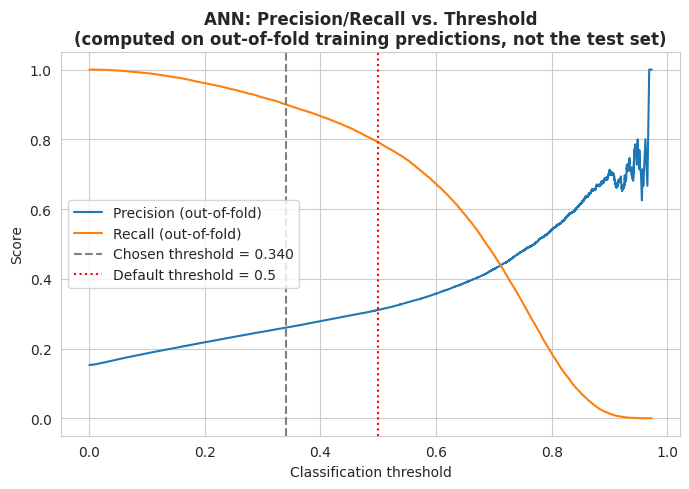

In [62]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(oof_thresholds, oof_precisions[:-1], label='Precision (out-of-fold)')
ax.plot(oof_thresholds, oof_recalls[:-1], label='Recall (out-of-fold)')
ax.axvline(chosen_threshold, color='gray', linestyle='--', label=f'Chosen threshold = {chosen_threshold:.3f}')
ax.axvline(0.5, color='red', linestyle=':', label='Default threshold = 0.5')
ax.set_xlabel('Classification threshold')
ax.set_ylabel('Score')
ax.set_title(f'{top_model}: Precision/Recall vs. Threshold\n(computed on out-of-fold training predictions, not the test set)', fontsize=12, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('threshold_tuning.png', dpi=150)
plt.show()


In [63]:
# The chosen threshold — selected entirely from out-of-fold training predictions above —
# is now applied to the test set for the first and only time, to report final metrics.
tuned_pred = (top_model_proba >= chosen_threshold).astype(int)
default_pred = (top_model_proba >= 0.5).astype(int)

tuned_metrics = evaluate_model(f'{top_model} @ threshold={chosen_threshold:.3f}', y_test, tuned_pred, top_model_proba)
default_metrics = evaluate_model(f'{top_model} @ threshold=0.5', y_test, default_pred, top_model_proba)

print("Comparison (both rows use the test set's predicted probabilities; only the cut-off differs):")
print(pd.DataFrame({'Default (0.5)': default_metrics, f'Tuned ({chosen_threshold:.3f})': tuned_metrics}).round(4))


--- ANN @ threshold=0.340 ---
              precision    recall  f1-score   support

 No Diabetes       0.97      0.53      0.69     38876
    Diabetes       0.26      0.91      0.40      7019

    accuracy                           0.59     45895
   macro avg       0.62      0.72      0.55     45895
weighted avg       0.86      0.59      0.65     45895

--- ANN @ threshold=0.5 ---
              precision    recall  f1-score   support

 No Diabetes       0.95      0.68      0.79     38876
    Diabetes       0.31      0.81      0.45      7019

    accuracy                           0.70     45895
   macro avg       0.63      0.74      0.62     45895
weighted avg       0.85      0.70      0.74     45895

Comparison (both rows use the test set's predicted probabilities; only the cut-off differs):
           Default (0.5)  Tuned (0.340)
Accuracy          0.6965         0.5919
Precision         0.3106         0.2605
Recall            0.8071         0.9078
F1-Score          0.4485         0.

Lowering the threshold below 0.5 increases Recall toward the 0.90 target at the cost of
Precision, since more borderline cases are now classified as positive. This trade-off is
made explicit rather than left at the default threshold, which is the direct consequence of
having set Recall as the priority metric in Section 5.10. The threshold itself was chosen
using only out-of-fold training predictions (Section 5.9), and the test set was used exactly
once, above, to report how that already-chosen threshold performs on genuinely unseen data.

## Step 6: Deployment Model, Operating Threshold, and Error Analysis

### 6.1 Choosing one model to deploy

Section 5.10 selects a model by the pre-defined rule (highest 10-fold CV mean Recall); in the
submitted execution of this notebook, that was the ANN. The
significance tests, however, found no significant Recall difference between the ANN and
XGBoost under either cross-validation test, so the rule identifies two statistically tied
candidates rather than a clear winner. A screening tool still needs **one** model, so a
tie-break is required. **Transparency note:** this tie-break was added after we observed,
across repeated executions of this notebook, that the ANN's architecture choice and Recall
change with the random seed. It is applied only between models that the CV-based tests
cannot separate. The tie-break criteria, in order:

1. **Reproducibility:** retraining must give the same model. XGBoost with a fixed seed is
   deterministic; the ANN's validation Recall moved between 0.774 and 0.802 across three
   seeds (Section 5.6b-2), and its selected architecture changed between executions.
2. **Stability across folds:** XGBoost's CV Recall standard deviation (0.0067) is about half
   of the ANN's (0.0118).
3. **Threshold-independent ranking quality:** XGBoost has the higher CV ROC-AUC (0.8150 vs.
   0.8128) and PR-AUC (0.4323 vs. 0.4253).
4. **Explainability:** exact SHAP values are available for XGBoost (Section 5.4b), so each
   referral can be explained to a clinician.

**Deployment model: XGBoost.** Because ANN training is not fully deterministic, a re-execution can change the ANN figures
quoted above, but XGBoost and everything derived from it below are reproduced exactly. The cells below tune XGBoost's threshold with the same out-of-fold method as
Section 5.11, then examine which diabetic respondents it still misses.

XGBoost threshold chosen on out-of-fold predictions (target Recall >= 0.9): 0.3520

XGBoost on the test set (applied once):
                       Default (0.5)  Deployed (0.352)
Recall                        0.7938            0.9058
Precision                     0.3152            0.2618
Accuracy                      0.7048            0.5950
F1-Score                      0.4513            0.4062
Missed cases (FN)          1447.0000          661.0000
False alarms (FP)         12103.0000        17928.0000
Flagged per true case         3.1721            3.8198


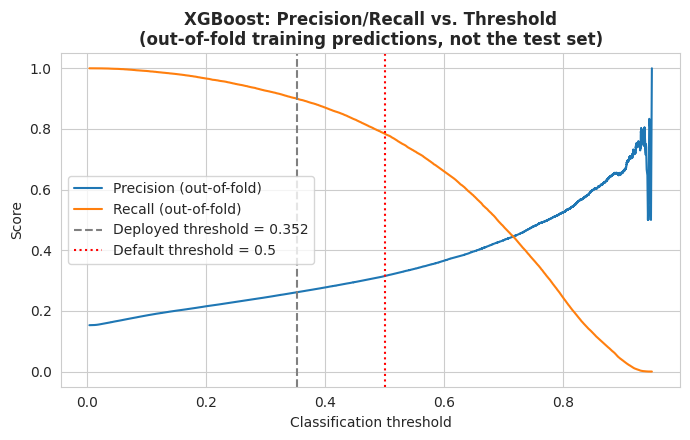

In [2]:
# Threshold tuning for the deployment model, on out-of-fold TRAINING predictions only
TARGET_RECALL = 0.90
prec_oof, rec_oof, thr_oof = precision_recall_curve(y_cv, oof_proba['XGBoost'])
valid = np.where(rec_oof[:-1] >= TARGET_RECALL)[0]
DEPLOY_THRESHOLD = thr_oof[valid[-1]]
print(f"XGBoost threshold chosen on out-of-fold predictions (target Recall >= {TARGET_RECALL}): {DEPLOY_THRESHOLD:.4f}")

xgb_test_proba = xgb_model.predict_proba(X_test)[:, 1]
def summarise(threshold):
    pred = (xgb_test_proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {'Recall': recall_score(y_test, pred), 'Precision': precision_score(y_test, pred),
            'Accuracy': accuracy_score(y_test, pred), 'F1-Score': f1_score(y_test, pred),
            'Missed cases (FN)': fn, 'False alarms (FP)': fp, 'Flagged per true case': (tp + fp) / tp}
deploy_table = pd.DataFrame({'Default (0.5)': summarise(0.5), f'Deployed ({DEPLOY_THRESHOLD:.3f})': summarise(DEPLOY_THRESHOLD)})
print("\nXGBoost on the test set (applied once):")
print(deploy_table.round(4).to_string())

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(thr_oof, prec_oof[:-1], label='Precision (out-of-fold)')
ax.plot(thr_oof, rec_oof[:-1], label='Recall (out-of-fold)')
ax.axvline(DEPLOY_THRESHOLD, color='grey', linestyle='--', label=f'Deployed threshold = {DEPLOY_THRESHOLD:.3f}')
ax.axvline(0.5, color='red', linestyle=':', label='Default threshold = 0.5')
ax.set_xlabel('Classification threshold'); ax.set_ylabel('Score'); ax.legend()
ax.set_title('XGBoost: Precision/Recall vs. Threshold\n(out-of-fold training predictions, not the test set)',
             fontsize=12, fontweight='bold')
plt.tight_layout(); plt.savefig('threshold_tuning_xgboost.png', dpi=150); plt.show()

### 6.2 Error analysis: who does the deployed model still miss?

At the deployed threshold, the false negatives (diabetic respondents predicted as healthy)
are compared with the true positives (diabetic respondents correctly flagged), and the miss
rate (FN / all diabetic respondents in the group) is broken down by key subgroups. False
positives are profiled alongside, to see whether false alarms look like genuinely healthy
people or like people at elevated risk.

Average profile by outcome on the test set (deployed threshold):
outcome                               TP     FN     FP     TN
Age band (1 = 18-24, 13 = 80+)      9.56   7.59   9.47   6.49
BMI                                32.57  27.30  30.29  26.28
GenHlth (1 = excellent, 5 = poor)   3.43   2.26   3.04   2.00
High blood pressure (%)            80.80  22.69  69.37  15.14
High cholesterol (%)               71.11  32.68  59.81  23.09
Difficulty walking (%)             41.05   7.56  27.42   4.75
Heart disease/attack (%)           24.46   3.93  16.10   1.66
Had cholesterol check (%)          99.59  96.82  99.39  91.77
Income band (1-8)                   5.06   6.10   5.51   6.44

Counts: {'TP': 6358, 'FN': 661, 'FP': 17928, 'TN': 20948}
Miss rate by BMI group: {'Under 25': 0.3015, '25 to 29.9': 0.1025, '30+': 0.0497}
Miss rate by Age group: {'18-39': 0.5127, '40-59': 0.146, '60+': 0.0514}
Miss rate by Self-rated health: {'Excellent/very good': 0.3127, 'Good': 0.0623, 'Fair/poor': 0.0195}


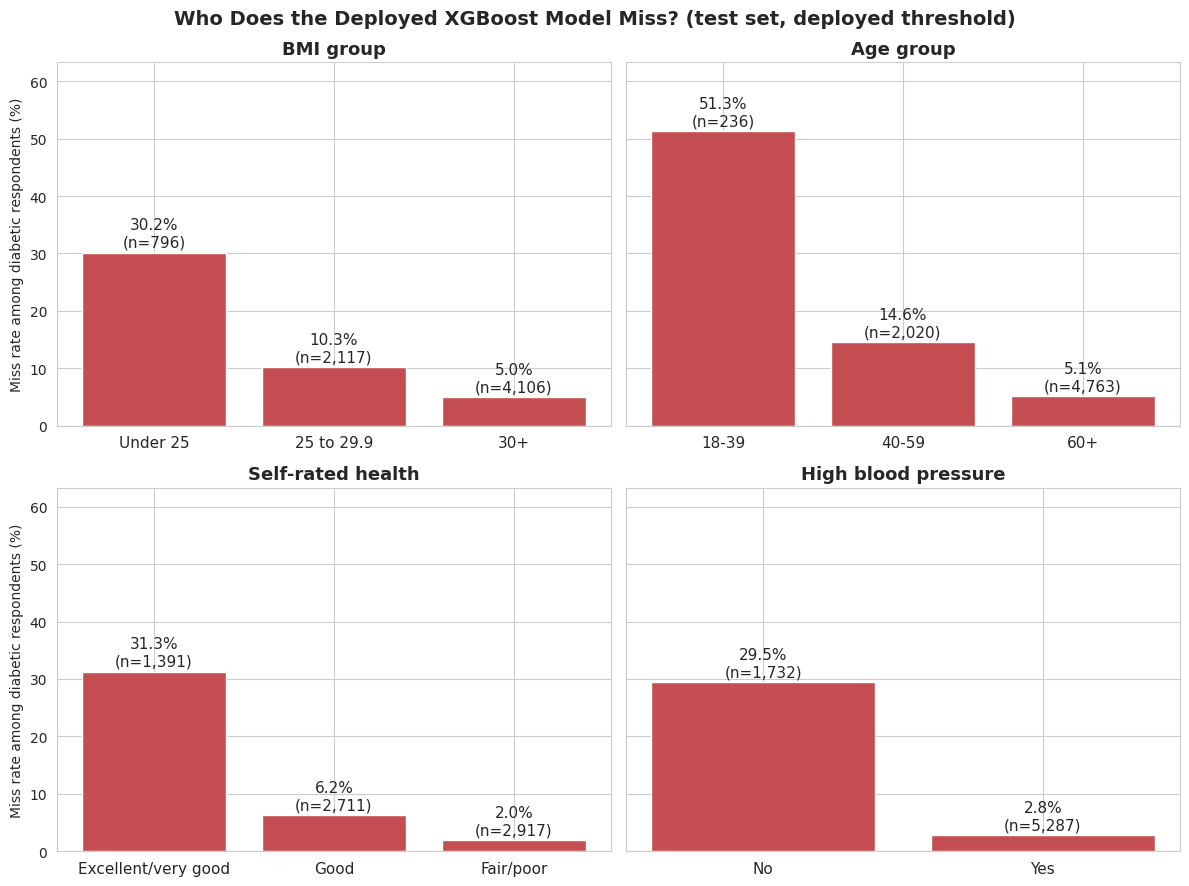


Diabetic respondents with no high BP, no high cholesterol and BMI < 30: 424 (6.0% of all diabetic respondents)
  Miss rate in this group: 53.3% vs. 6.6% for everyone else
  Share of all missed cases that come from this group: 34.2%


In [3]:
pred_deploy = (xgb_test_proba >= DEPLOY_THRESHOLD).astype(int)
test_df = X_test.copy(); test_df['actual'] = y_test.values; test_df['pred'] = pred_deploy
outcome = np.select([(test_df.actual == 1) & (test_df.pred == 1), (test_df.actual == 1) & (test_df.pred == 0),
                     (test_df.actual == 0) & (test_df.pred == 1)], ['TP', 'FN', 'FP'], 'TN')
test_df['outcome'] = outcome

profile_cols = {'Age band (1 = 18-24, 13 = 80+)': 'Age', 'BMI': 'BMI', 'GenHlth (1 = excellent, 5 = poor)': 'GenHlth',
                'High blood pressure (%)': 'HighBP', 'High cholesterol (%)': 'HighChol',
                'Difficulty walking (%)': 'DiffWalk', 'Heart disease/attack (%)': 'HeartDiseaseorAttack',
                'Had cholesterol check (%)': 'CholCheck', 'Income band (1-8)': 'Income'}
profile = pd.DataFrame({label: test_df.groupby('outcome')[col].mean() for label, col in profile_cols.items()}).T
for label in profile.index:
    if '(%)' in label: profile.loc[label] *= 100
profile = profile[['TP', 'FN', 'FP', 'TN']]
print("Average profile by outcome on the test set (deployed threshold):")
print(profile.round(2).to_string())
print("\nCounts:", test_df['outcome'].value_counts().reindex(['TP', 'FN', 'FP', 'TN']).to_dict())

pos = test_df[test_df.actual == 1].copy()
pos['BMI group'] = pd.cut(pos.BMI, [0, 25, 30, 200], right=False, labels=['Under 25', '25 to 29.9', '30+'])
pos['Age group'] = pd.cut(pos.Age, [0, 4, 8, 13], labels=['18-39', '40-59', '60+'])
pos['Self-rated health'] = pd.cut(pos.GenHlth, [0, 2, 3, 5], labels=['Excellent/very good', 'Good', 'Fair/poor'])
pos['High blood pressure'] = pos.HighBP.map({0: 'No', 1: 'Yes'})
pos['missed'] = (pos.pred == 0).astype(int)

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharey=True)
for ax, g in zip(axes.ravel(), ['BMI group', 'Age group', 'Self-rated health', 'High blood pressure']):
    rates = pos.groupby(g, observed=True)['missed'].agg(['mean', 'size'])
    ax.bar(rates.index.astype(str), rates['mean'] * 100, color='#C44E52')
    for i, (r, n) in enumerate(zip(rates['mean'], rates['size'])):
        ax.text(i, r * 100 + 1.0, f'{r:.1%}\n(n={n:,})', ha='center', fontsize=11)
    ax.set_title(g, fontsize=13, fontweight='bold'); ax.tick_params(axis='x', labelsize=11)
    print(f"Miss rate by {g}:", {k: round(v, 4) for k, v in rates['mean'].items()})
for ax in axes[:, 0]:
    ax.set_ylabel('Miss rate among diabetic respondents (%)')
max_rate = max(pos.groupby(g, observed=True)['missed'].mean().max() for g in
               ['BMI group', 'Age group', 'Self-rated health', 'High blood pressure'])
axes[0, 0].set_ylim(0, max_rate * 100 + 12)  # shared y-axis: leave room for the tallest bar's label
plt.suptitle('Who Does the Deployed XGBoost Model Miss? (test set, deployed threshold)', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.savefig('error_analysis_missed_cases.png', dpi=150); plt.show()

low_marker = (pos.HighBP == 0) & (pos.HighChol == 0) & (pos.BMI < 30)
print(f"\nDiabetic respondents with no high BP, no high cholesterol and BMI < 30: {low_marker.sum():,} "
      f"({low_marker.mean():.1%} of all diabetic respondents)")
print(f"  Miss rate in this group: {pos.loc[low_marker, 'missed'].mean():.1%} vs. "
      f"{pos.loc[~low_marker, 'missed'].mean():.1%} for everyone else")
print(f"  Share of all missed cases that come from this group: {pos.loc[low_marker, 'missed'].sum() / pos.missed.sum():.1%}")

The missed diabetic respondents are concentrated among people who **lack the classic risk
markers** the model has learned to rely on: younger respondents, those without high blood
pressure or high cholesterol, those with lower BMI, and those who rate their own health as
good. In survey terms they look like non-diabetic respondents, so no threshold on these
features can catch them without also flagging a very large number of healthy people. This is
a limitation of the information in the survey, not of a particular algorithm, and it points
to where a survey-based screen should be complemented by routine blood glucose testing.

## Conclusion

This notebook compared five classification models for predicting diabetes/prediabetes from
the BRFSS 2015 Diabetes Health Indicators dataset, under a strong class imbalance (84.71% vs.
15.29% after removing exact duplicate rows, Section 2.1b). All modelling decisions were made
on the training set only: feature selection, transformations, scaling, imbalance handling and
the Naive Bayes feature-set choice used training data or training-set cross-validation; the
ANN's architecture and hyperparameters were selected on a held-out validation split; and the
classification threshold was chosen on out-of-fold training predictions (Sections 5.11 and
6.1). The test set is used once per model to report final metrics (Section 5.7); later
analyses only reuse those stored predictions and change no modelling decision.

**Model ranking (submitted execution).** With Recall on the positive class as the priority
metric, the ANN achieved the highest mean 10-fold CV Recall (0.7912 ± 0.0118), ahead of
XGBoost (0.7845 ± 0.0067). XGBoost, however, had the highest CV ROC-AUC (0.8150 vs. 0.8128)
and PR-AUC (0.4323 vs. 0.4253), so the ANN's Recall lead at the 0.5 threshold reflects where
its predicted probabilities sit relative to that cut-off more than better ranking of cases.

**Statistical tests.** The ANN's lead was checked with three complementary tests (Sections
5.10 to 5.10b):
- vs. XGBoost: neither CV-based test found a significant difference (Wilcoxon p = 0.2852,
  corrected resampled t-test p = 0.3233), while the paired bootstrap did.
- vs. Decision Tree: the Wilcoxon test (p = 0.0371) and the bootstrap found a significant
  difference, but the corrected t-test, which adjusts for the overlap between CV training
  folds (Nadeau & Bengio, 2003), did not (p = 0.1022).
- vs. Random Forest and Naive Bayes: all three tests found a significant difference.

These disagreements are reported rather than resolved in whichever direction gives the
cleaner story. The CV-based tests measure robustness across ten different training sets,
while the bootstrap only resamples one fixed test set, and the uncorrected Wilcoxon test is
known to be over-optimistic when folds share training data (Dietterich, 1998). The ANN and
XGBoost are therefore treated as statistically tied on Recall.

**Deployment model.** ANN training is not fully deterministic on CPU, so re-executing this
notebook can change the ANN's figures and even which model ranks first by CV Recall, while
all other models reproduce exactly. Step 6 therefore resolves the ANN/XGBoost tie with a
stated tie-break (reproducibility, stability across folds, threshold-independent ranking
quality, explainability) and selects **XGBoost** for deployment, with a threshold of 0.352
chosen on out-of-fold training predictions. On the test set it reaches Recall 0.9058 and
Precision 0.2618, almost identical to the ANN tuned to the same 90% Recall target (Recall
0.9078, Precision 0.2605, Section 5.11). The error analysis (Section 6.2) shows that the
remaining missed cases are concentrated among younger, leaner respondents without high blood
pressure, who look like non-diabetic respondents on these survey features.

**Other findings.** Naive Bayes was the weakest model, consistent with its Gaussian
assumption being violated by the largely binary feature set (Section 5.5b); applying log1p
to the three strongly skewed features raised its CV Recall from 0.7270 to 0.7481 (Section
5.5c), but it remained last. Section 4.2b showed that SMOTE lowers Recall sharply on this
dataset, while class weighting and random undersampling are statistically tied on Recall;
class weighting was kept because it uses the full training set. Across all models, higher
Recall could only be obtained at a real cost to Precision and Accuracy, which is expected
when predicting a chronic condition from self-reported survey data rather than clinical
measurements.

**Comparison with published results.** Islam et al. (2025), using this same dataset, report
ROC-AUC of about 0.96 for single tree-based models and 0.989 for a stacking ensemble after
rebalancing with SMOTE and Tomek Links. In the same study, their simpler baselines, Logistic
Regression (ROC-AUC = 0.8135) and Naive Bayes (ROC-AUC = 0.7750), sit close to the values
obtained here (0.77 to 0.82). The paper does not state whether resampling was applied before
or after the train/test split; if synthetic rows were created before the split, near-copies
of training rows would reach the test set and inflate the reported scores. The gap may
therefore reflect evaluation design rather than a higher achievable ceiling, but this cannot
be confirmed from the paper itself.

**Clinical caveat.** Several of the strongest predictors (`GenHlth`, `DiffWalk`, and to some
extent `HighBP`) are plausibly consequences of diabetes-related complications as much as
pre-existing risk factors, and the BRFSS survey captures each respondent at a single point in
time, so the data cannot establish which came first. The models therefore show that diabetes
status can be recognised from concurrent self-reported indicators, which is a weaker claim
than identifying early warning signs that precede diagnosis.

**Future work:** averaging ANN results over several random seeds before model selection;
engineering interaction features (e.g. BMI category combined with age group); a sensitivity
analysis that retains the duplicate rows removed in Section 2.1b; cost-sensitive learning
with an explicit cost ratio between false negatives and false positives; and validation on
newer or longitudinal BRFSS data.

**References for this section:** Dietterich, T. G. (1998). Approximate statistical tests
for comparing supervised classification learning algorithms. *Neural Computation, 10*(7),
1895-1923. Islam, M. N., Rimon, M. M. H., Shamim, S. S. A., Fahad, Z. M., Mony, M. J. I., &
Chowdhury, M. J. U. (2025). *An improved ensemble-based machine learning model with feature
optimization for early diabetes prediction* (arXiv:2512.02023). arXiv. Nadeau, C., &
Bengio, Y. (2003). Inference for the generalization error. *Machine Learning, 52*(3),
239-281.